# Cyanobacteria detection from water reflectance — D², phycocyanin trough and normalisation sensitivity (v2)

**Purpose.** (1) Detect cyanobacteria in a reflectance time series from any hyperspectral or CHIME-like sensor,
(2) quantify whether the normalisation applied before the second derivative changes the detection, and
(3) validate the detection against in-situ taxonomy when it is available.

**Datasets.** Choose one with `DATASET` in §1. Configured: L. Võrtsjärv (Hypstar), Södra Bergundasjön (WISP),
Mälaren-Görväln (CHIME, simulated), Dalarö (CHIME, simulated; sampling dates or daily). Any other sensor can be added
with the `my_sensor` template. Figures and summary tables are written with the dataset key in the file name, so runs
on different datasets do not overwrite each other, and §14 compares all datasets that have been run.

**All spectral computations come from `phytospec.cyano`** (no local re-implementation in this notebook).

## Detection features

| Feature | Physical meaning | Cy+ rule | Status |
|---|---|---|---|
| `D2_620` | curvature of the phycocyanin absorption trough (~620 nm) | D²(620) **> 0** | main feature |
| `D2_552` | curvature of the green reflectance peak | D²(552.5) **< 0** | legacy (v1), kept for comparison |

Detection relies on the second derivative only. A trough-depth index (relative depth at ~622 nm) was evaluated during
development and dropped: it carries the same information as D²(620).

## Normalisation question

> *Does the wavelength used to normalise the spectrum before computing D² change the sign, the amplitude or the
> detection skill of D²?*

| ID | Normalisation |
|---|---|
| `raw` | none — D² of the reflectance itself |
| `442` | ρ(442.5 nm) |
| `620` | ρ(620 nm) — Lubac et al. (2008) convention, phycocyanin absorption |
| `665` | ρ(665 nm) |

## What changed with respect to v1 of this notebook

| # | v1 | v2 | Why |
|---|---|---|---|
| 1 | "442.5 nm" normalisation taken as grid **index 35** | normalisation wavelengths always explicit; spectra with ρ(λn) ≤ 0 are rejected and counted | on the Hypstar grid index 35 is 366.7 nm, not 442.5 nm |
| 2 | `raw` case computed with a local double `np.gradient`, normalised cases with `phytospec` | one 3-point formula for every case (`cy.second_derivative`), checked against `phytospec.algorithms.compute_D2` | dividing by ρ(λn) > 0 cannot change the sign of D²: the v1 differences (raw 80 %, 442.5 nm 75 %, 620/665 nm 76 %) reflect the different raw formula and the 366.7 nm normalisation, not the choice of normalisation wavelength |
| 3 | smoothing = 2 passes of a 5-point mean (width in **samples**) | Gaussian smoothing to a target resolution in **nm**; none for noise-free simulated spectra | a width in samples means a different physical resolution on every sensor |
| 4 | only D²(552.5) | D²(620) added as main feature; D²(552.5) kept as legacy | D²(552.5) follows the green-peak position, not phycocyanin |
| 5 | QC: visible maximum only | + negatives, NaN gaps, glint, acquisition time, irradiance, spectral spikes, duplicated timestamps | pathological spectra produced isolated extreme D² values |
| 6 | single hard-coded dataset | dataset registry, sensor-independent loaders, pre-flight checks | same analysis on Võrtsjärv, Södra, Görväln, Dalarö |
| 7 | no validation | in-situ match-ups: confusion matrix, sensitivity, false-positive rate, FAR, CSI, KSS, AUC, Spearman ρ, with confidence intervals | the objective is detection, not only the sign of an index |
| 8 | sign agreement read from plots | sign agreement, amplitude, rank correlation and AUC tabulated per normalisation | quantitative answer to the normalisation question |

## 1. Imports and configuration

In [133]:
import re, warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.gridspec as gridspec
from IPython.display import display
from scipy.ndimage import median_filter, gaussian_filter1d
from scipy.stats import spearmanr, rankdata, norm as normal_dist
warnings.filterwarnings('ignore', category=RuntimeWarning)   # all-NaN slices in nan-aware statistics

# phytospec is REQUIRED: every spectral computation comes from phytospec.cyano, so notebook and package cannot diverge.
from phytospec import config as cfg
from phytospec import cyano as cy
from phytospec import algorithms as alg          # only for the formula-consistency check in §5.2

_API = ['SMOOTH_FWHM', 'D2_WL_PC', 'D2_WL_LEGACY', 'DESIGN_STEP', 'check_grid', 'prepare_spectra',
        'cyano_features', 'second_derivative', 'd2_at', 'bracketing_bands', 'nearest_band']
_missing = [f'cyano.{n}' for n in _API if not hasattr(cy, n)]
_missing += [f'config.{n}' for n in ('DATA_RAW', 'FIGURES_DIR', 'CY_SMOOTH_FWHM', 'CY_DOM_FRAC') if not hasattr(cfg, n)]
if _missing:
    raise ImportError(f'The installed phytospec does not provide {_missing}. Update phytospec and restart the kernel.')

FIG_DIR = Path(cfg.FIGURES_DIR); FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.spines.top': False, 'axes.spines.right': False})
print(f'phytospec.cyano defaults: smoothing {cy.SMOOTH_FWHM} nm | D² at {cy.D2_WL_PC} nm (legacy {cy.D2_WL_LEGACY} nm) '
      f'| design step {cy.DESIGN_STEP} nm')

phytospec.cyano defaults: smoothing 10.0 nm | D² at 620.0 nm (legacy 552.5 nm) | design step 2.5 nm


In [134]:
DATA = Path(cfg.DATA_RAW)

# ── In-situ taxonomy (optional) ───────────────────────────────────────────────
# layout 'wide': one row per sample, a total-biomass column and a cyanobacteria column
# layout 'long': one row per taxon/group; summed per date (groups in exclude_groups are dropped from the total)
INSITU = {
    'sodra': dict(file=DATA / 'sodra' / 'Södra_Bergundasjön_all_physical_chemical_taxonomic_and_pigment_groups_all_years.xlsx',
                  layout='wide', sheet=0, date_col='Date',
                  total_col='Total phytoplankton biomass (mg/L) at 0-2 m', cyano_col='Cyanobacteria (mm3/l=mg/L)',
                  cyano_nan_as_zero=False),
    'gorvaln': dict(file=DATA / 'gorvaln' / 'Görväln_all_phys_chem_chla_and_phytobiomass_2015-2024.xlsx',
                    layout='wide', sheet='Phytoplankton', date_col='Date',
                    total_col='Total biomass (mm3/l)', cyano_col='Cyanobacteria (mm3/l)',
                    cyano_nan_as_zero=True),          # empty cell = group not found in the sample
    'dalaro': dict(file=DATA / 'dalaro' / 'Results_Phytoplankton_Dalarö.xlsx',
                   layout='long', sheet='Aquatime_Phytoplankton', date_col='Sampling date', date_format='%d.%m.%Y',
                   group_col='Taxonomic Group', value_col='Biomass (µg/l)', cyano_groups=['Cyanophyta'],
                   exclude_groups=['CILIOPHORA', 'PROTOZOA INCERTAE SEDIS']),   # heterotrophs
    'vortsjarv': dict(file=DATA / 'vortsjarv' / 'Phytoplankton.xlsx',
                      layout='long', sheet=0, date_col='datetime', site_col='site_id', site='V10',
                      group_col='class', value_col='biomass [mg/dm3]', cyano_groups=['Cyanophyceae'],
                      exclude_groups=[]),
}

# ── Spectral datasets ─────────────────────────────────────────────────────────
#   fmt          loader (§2): 'hypstar_csv' | 'wispcloud_xlsx' | 'convolved_csv' | 'generic_wide'
#   refl         'rhow' (dimensionless) or 'Rrs' [sr-1]
#   native_fwhm  instrument resolution [nm] from the datasheet (None → sampling interval)
#   tz           time zone of the timestamps (None if dates only)
#   simulated    True for noise-free simulated spectra (MOMO): no smoothing, no SNR classes
#   insitu       key of INSITU or None;  match_days: max. distance spectrum ↔ sample [days]
DATASETS = {
    'vortsjarv_hypstar': dict(file=DATA / 'vortsjarv' /'Hypstar_radiometric_23-24.csv', fmt='hypstar_csv',
                              station='L. Võrtsjärv (Hypstar)', refl='rhow', native_fwhm=3.0, tz=None,
                              simulated=False, insitu='vortsjarv', match_days=1),
    'sodra_wisp':        dict(file=DATA / 'sodra' / 'WISP_Spectra_SWE_Södra_Bergundasjön_2024.xlsx', fmt='wispcloud_xlsx',
                              station='Södra Bergundasjön (WISP)', refl='Rrs', native_fwhm=5.0, tz='UTC',
                              simulated=False, insitu='sodra', match_days=1),
    'gorvaln_chime_sim': dict(file=DATA / 'gorvaln' / 'AQUATIME_D2.1.0_RD-malaren_daily_combined_fluo-chime-simulated-RrsNoGlint_v0.4.csv',
                              fmt='convolved_csv', station='Mälaren-Görväln (CHIME, MOMO-simulated)', refl='Rrs',
                              native_fwhm=None, tz='UTC', simulated=True, insitu='gorvaln', match_days=0),
    'dalaro_chime_sim':  dict(file=DATA / 'dalaro' / 'AQUATIME_D2.1.0_RD-dalaro_irregular_fluo-chime-simulated-RrsNoGlint_v0.4.csv',
                              fmt='convolved_csv', station='Dalarö (CHIME, MOMO-simulated, sampling dates)', refl='Rrs',
                              native_fwhm=None, tz='UTC', simulated=True, insitu='dalaro', match_days=0),
    'dalaro_chime_sim_daily': dict(file=DATA / 'dalaro' / 'AQUATIME_D2.1.0_RD-dalaro_daily_fluo-chime-simulated-RrsNoGlint_v0.4.csv',
                              fmt='convolved_csv', station='Dalarö (CHIME, MOMO-simulated, daily)', refl='Rrs',
                              native_fwhm=None, tz='UTC', simulated=True, insitu='dalaro', match_days=0),
    # ── TEMPLATE for any other sensor: copy, rename and edit ───────────────────
    'my_sensor':         dict(file=DATA / 'my_sensor_spectra.csv', fmt='generic_wide',
                              station='My lake (My sensor)', refl='Rrs', native_fwhm=None, tz='UTC',
                              simulated=False, insitu=None, match_days=1,
                              loader_opts=dict(time_col='datetime', time_format=None, wl_prefix=None,
                                               sheet=None, sep=',', skiprows=0)),
}

DATASET = 'dalaro_chime_sim_daily'          # ← 'vortsjarv_hypstar' | 'sodra_wisp' | 'gorvaln_chime_sim' | 'dalaro_chime_sim' | 'dalaro_chime_sim_daily'

if DATASET not in DATASETS:
    raise KeyError(f'DATASET "{DATASET}" is not configured. Options: {list(DATASETS)}')
DS = {'native_fwhm': None, 'tz': None, 'loader_opts': {}, 'simulated': False, 'insitu': None, 'match_days': 1,
      **DATASETS[DATASET]}
STATION = DS['station']

def fig_path(name):
    """Figure file name tagged with the dataset key (runs on different datasets never overwrite each other)."""
    return FIG_DIR / f'05v2_{DATASET}_{name}.png'

# ── Processing ────────────────────────────────────────────────────────────────
SMOOTH_FWHM = DS.get('smooth_fwhm', None if DS['simulated'] else cfg.CY_SMOOTH_FWHM)   # nm, None = none
NORM_WL     = None       # normalisation used by the detection itself (the sign never depends on it, §11); None = raw
USE_SNR     = not DS['simulated']       # noise-free simulations: classify by the rule only
SNR_MIN     = 1.0        # |value − threshold| / noise below this → 'undetermined'
N_MC        = 100        # Monte-Carlo realisations (one spectrum per day)
CY_DOM_FRAC = cfg.CY_DOM_FRAC           # in-situ: cyano-dominated if ≥ this share of the phytoplankton biomass
MAIN_FEATURE = 'D2_620'

# Decision rules: feature → (threshold, direction); Cy+ if direction·(value − threshold) > 0
RULES = {'D2_620': (0.0, +1), 'D2_552': (0.0, -1)}
FEATS_ALL = list(RULES)                  # main feature first
FEAT_LABEL = {'D2_620': 'D²(620) — phycocyanin trough', 'D2_552': 'D²(552.5) — legacy green peak'}
FEAT_COL = {'D2_620': '#c0392b', 'D2_552': '#6a0dad'}
FEAT_WL = {'D2_620': cy.D2_WL_PC, 'D2_552': cy.D2_WL_LEGACY}

# ── Normalisation sensitivity (§11) ───────────────────────────────────────────
#   (key, normalisation wavelength [nm] or None = raw, label, colour)
NORMS = [('raw', None,  'No normalisation',          '#1b7837'),
         ('442', 442.5, 'Norm 442.5 nm',             '#2166ac'),
         ('620', 620.0, 'Norm 620 nm (Lubac 2008)',  '#d6604d'),
         ('665', 665.0, 'Norm 665 nm',               '#b58900')]
SENS_FEATURE = MAIN_FEATURE              # feature shown in the §11 figures (tables cover both D² features)

# ── Statistics ────────────────────────────────────────────────────────────────
CI_LEVEL = 0.95          # confidence level: Wilson intervals (rates), stratified bootstrap (AUC)
N_BOOT   = 2000
RNG_SEED = 42

# ── Quality control ───────────────────────────────────────────────────────────
RHO_MAX       = 0.10 if DS['refl'] == 'rhow' else 0.10 / np.pi   # open-water upper bound (ice/snow)
NAN_MAX_FRAC  = 0.05     # max. NaN fraction in 400–700 nm
MAX_GAP_BANDS = 2        # max. consecutive NaN bands in 400–700 nm (longer gaps cannot be interpolated)
GLINT_RATIO   = 0.5      # reject if median R(840–860) ≥ 0.5 · max R(540–590)
TIME_WINDOW   = (8, 14)  # keep 08:00 ≤ t < 14:00 UTC when timestamps carry a time; None = all
ED_MIN_FRAC   = 0.5      # only if Ed is available: keep Ed(550) ≥ 50 % of the daily maximum
SPIKE_Z, SPIKE_MIN = 8.0, 0.02   # spectral spike: robust z-score and minimum relative size
FLAT_RATIO    = 1.5      # ice/snow test: R(560)/R(440) below this = spectrally flat (white surface)
print(f'Dataset: {DATASET} → {DS["file"]}  (exists: {Path(DS["file"]).exists()})')
print(f'Simulated: {DS["simulated"]} | smoothing: {SMOOTH_FWHM} nm | SNR classes: {USE_SNR} | rules: {RULES}')

Dataset: dalaro_chime_sim_daily → C:\Users\gvillegas\OneDrive - Institute of Natural Sciences\Projects\REMSEM\aquatime\AQUAPHYTO\data\raw\dalaro\AQUATIME_D2.1.0_RD-dalaro_daily_fluo-chime-simulated-RrsNoGlint_v0.4.csv  (exists: True)
Simulated: True | smoothing: None nm | SNR classes: False | rules: {'D2_620': (0.0, 1), 'D2_552': (0.0, -1)}


## 2. Load spectra
Loaders return `(times, wavelengths, reflectance (n, λ), Ed or None)`. Duplicated timestamps are removed and all
times are converted to UTC. In the code `RHOW` holds the reflectance in the unit given by `refl` (ρw or Rrs).

In [135]:
WL_RE = re.compile(r'(\d{3,4}(?:\.\d+)?)')

def load_hypstar_csv(path, **_):
    df = pd.read_csv(path)
    t = pd.to_datetime(df['Date'].astype(str), format='%Y%m%d')
    wl = df.columns[1:].astype(float).values
    return pd.DatetimeIndex(t), wl, df.iloc[:, 1:].to_numpy(float), None

def load_wispcloud_xlsx(path, block='level2.reflectance', **_):
    xl = pd.ExcelFile(path); T, RR, EE = [], [], []
    for sh in xl.sheet_names:
        df = pd.read_excel(xl, sh, header=None)
        hr = df.index[df.iloc[:, 0].astype(str).str.strip() == 'ID'][0]
        starts = {str(v).split(' (')[0].strip().replace(',', '.'): i
                  for i, v in df.iloc[hr - 1].items() if pd.notna(v) and i >= 4}
        body = df.iloc[hr + 1:].reset_index(drop=True)
        def blk(name):
            i0 = starts[name]
            hdr = pd.to_numeric(df.iloc[hr, i0:i0 + 600], errors='coerce').values
            n = int(np.argmax(np.diff(hdr) <= 0) + 1) if np.any(np.diff(hdr) <= 0) else len(hdr)
            return hdr[:n].astype(float), body.iloc[:, i0:i0 + n].apply(pd.to_numeric, errors='coerce').to_numpy(float)
        wl_, R_ = blk(block); _, E_ = blk('ed.irradiance')
        T.append(pd.to_datetime(body[2].astype(str).str[:10] + ' ' + body[3].astype(str), format='mixed'))
        RR.append(R_); EE.append(E_)
    return pd.DatetimeIndex(pd.concat(T).values), wl_, np.vstack(RR), np.vstack(EE)

def load_convolved_csv(path, **_):
    df = pd.read_csv(path); cand = {}
    for c in df.columns:
        m = WL_RE.search(str(c))
        if m and 350 <= float(m.group(1)) <= 1000 and pd.api.types.is_numeric_dtype(df[c]):
            cand[c] = (WL_RE.sub('', str(c)), float(m.group(1)))
    prefix = pd.Series([p for p, _ in cand.values()]).mode()[0]
    cols = [c for c, (p, _) in cand.items() if p == prefix]
    other = [c for c in df.columns if c not in cols]
    tcol = next((c for c in other if any(k in str(c).lower() for k in ('date', 'time'))), other[0])
    wl_ = np.array([cand[c][1] for c in cols]); o = np.argsort(wl_)
    print(f'Spectral family "{prefix}": {len(cols)} bands | other columns: {other} (time column: "{tcol}")')
    return pd.DatetimeIndex(pd.to_datetime(df[tcol])), wl_[o], df[cols].to_numpy(float)[:, o], None

def load_generic_wide(path, time_col='datetime', time_format=None, wl_prefix=None, sheet=None,
                      sep=',', skiprows=0, **_):
    """TEMPLATE loader: one row per spectrum, one time column, one column per wavelength."""
    p = str(path).lower()
    df = (pd.read_excel(path, sheet_name=sheet or 0, skiprows=skiprows) if p.endswith(('xlsx', 'xls'))
          else pd.read_csv(path, sep=sep, skiprows=skiprows))
    if time_col not in df.columns:
        raise KeyError(f'time_col "{time_col}" not found. Available columns: {list(df.columns)[:15]} …')
    if wl_prefix is None:
        pref = [re.match(r'^(.*?)(\d{3,4}(?:\.\d+)?)$', str(c)) for c in df.columns]
        pref = [m.group(1) for m in pref if m and 300 <= float(m.group(2)) <= 1100]
        wl_prefix = pd.Series(pref).mode()[0] if pref else ''
        print(f'Auto-detected wavelength column prefix: "{wl_prefix}"')
    cols, wls = [], []
    for c in df.columns:
        name = str(c)
        if not name.startswith(wl_prefix):
            continue
        try:
            v = float(name[len(wl_prefix):])
        except ValueError:
            continue
        if 300 <= v <= 1100:
            cols.append(c); wls.append(v)
    if len(cols) < 3:
        raise ValueError(f'Only {len(cols)} wavelength columns found with prefix "{wl_prefix}".')
    t = df[time_col]
    t = pd.to_datetime(t.astype(str), format=time_format) if time_format else pd.to_datetime(t)
    wls = np.array(wls); o = np.argsort(wls)
    return pd.DatetimeIndex(t), wls[o], df[cols].apply(pd.to_numeric, errors='coerce').to_numpy(float)[:, o], None

LOADERS = {'hypstar_csv': load_hypstar_csv, 'wispcloud_xlsx': load_wispcloud_xlsx,
           'convolved_csv': load_convolved_csv, 'generic_wide': load_generic_wide}
if not Path(DS['file']).exists():
    raise FileNotFoundError(f'{DS["file"]} not found — check DATASETS["{DATASET}"]["file"].')
t_all, wl, RHOW_all, ED_all = LOADERS[DS['fmt']](DS['file'], **DS['loader_opts'])

# ── times in UTC (naive) ──────────────────────────────────────────────────────
if t_all.tz is not None:
    t_all = t_all.tz_convert('UTC').tz_localize(None)
elif DS['tz'] and (t_all.hour != 0).any():
    t_all = t_all.tz_localize(DS['tz']).tz_convert('UTC').tz_localize(None)

# ── sort and drop duplicated timestamps ───────────────────────────────────────
N_LOADED = len(t_all)
o = np.argsort(t_all.values, kind='stable'); t_all, RHOW_all = t_all[o], RHOW_all[o]
ED_all = ED_all[o] if ED_all is not None else None
keep = ~t_all.duplicated(keep='first')
N_DUP = int((~keep).sum())
t_all, RHOW_all = t_all[keep], RHOW_all[keep]
ED_all = ED_all[keep] if ED_all is not None else None
if len(t_all) < 3:
    raise RuntimeError(f'Only {len(t_all)} spectra loaded from {DS["file"]} — nothing to analyse.')

delta_native = cy.check_grid(wl)
print(f'Station     : {STATION}')
print(f'Spectra     : {len(t_all)} ({N_DUP} duplicated timestamps removed)  {t_all.min().date()} → {t_all.max().date()}')
print(f'Wavelengths : {len(wl)} ({wl[0]:.1f}–{wl[-1]:.1f} nm), median Δλ = {delta_native:.3f} nm')

Spectral family "": 71 bands | other columns: ['date', 'QWIP'] (time column: "date")
Station     : Dalarö (CHIME, MOMO-simulated, daily)
Spectra     : 182 (0 duplicated timestamps removed)  2024-03-27 → 2024-09-24
Wavelengths : 71 (404.2–992.2 nm), median Δλ = 8.400 nm


## 2b. Pre-flight checks
`FAIL` stops the notebook with an explanation; `WARN` lets it run and is carried to the summary (§14).

In [136]:
checks = []
def check(name, status, msg):
    checks.append({'check': name, 'status': status, 'detail': msg})

dwl = np.diff(wl)
irr = np.ptp(dwl) / np.median(dwl)
check('Wavelength grid', 'OK' if irr < 0.5 else 'WARN',
      f'Δλ median {np.median(dwl):.3f} nm, range {dwl.min():.3f}–{dwl.max():.3f} nm'
      + ('' if irr < 0.5 else ' — irregular grid: the non-uniform 3-point formula is used'))

need = {'D²(552.5) (legacy)': (535, 570), 'D²(620) (phycocyanin band)': (595, 650)}
for name, (lo, hi) in need.items():
    ok = wl[0] <= lo and wl[-1] >= hi
    check(f'Coverage: {name}', 'OK' if ok else 'FAIL', f'needs {lo}–{hi} nm, data {wl[0]:.0f}–{wl[-1]:.0f} nm')

native_res = max(delta_native, DS['native_fwhm'] or 0.0)
if DS['native_fwhm'] is None:
    check('Native FWHM', 'WARN', 'not provided → assumed equal to the sampling interval (set it from the datasheet)')
n_trough = int(((wl >= 595) & (wl <= 650)).sum())
if n_trough < 5:
    check('Resolution', 'FAIL', f'only {n_trough} bands in 595–650 nm: the phycocyanin trough cannot be resolved '
          '(multispectral / broad-band sensor)')
else:
    check('Resolution', 'OK' if native_res <= 5 else 'WARN',
          f'native resolution {native_res:.1f} nm, {n_trough} bands in 595–650 nm'
          + ('' if native_res <= 5 else ' — coarse: D² is evaluated on the native bands; magnitudes are not '
             'comparable with hyperspectral sensors and thresholds must be calibrated for this sensor'))
if SMOOTH_FWHM is not None and SMOOTH_FWHM < native_res:
    check('Smoothing', 'WARN', f'SMOOTH_FWHM {SMOOTH_FWHM} nm < native resolution {native_res:.1f} nm → no smoothing applied')

med_max = np.nanmedian(np.nanmax(RHOW_all[:, (wl >= 400) & (wl <= 700)], axis=1))
expect = {'Rrs': (1e-4, 0.03), 'rhow': (3e-4, 0.10)}[DS['refl']]
other = 'rhow' if DS['refl'] == 'Rrs' else 'Rrs'
check('Units', 'OK' if expect[0] <= med_max <= expect[1] else 'WARN',
      f'median visible maximum {med_max:.4f} with refl="{DS["refl"]}"'
      + ('' if expect[0] <= med_max <= expect[1] else f' — outside the typical range; is it "{other}" (×π) or percent?'))

has_time = bool((t_all.hour != 0).any())
if has_time and DS['tz'] is None:
    check('Time zone', 'WARN', 'timestamps have a time of day but tz=None → assumed UTC for TIME_WINDOW')
if N_DUP:
    check('Duplicated timestamps', 'WARN', f'{N_DUP} duplicated timestamps removed (first kept)')
nan_frac = float(np.isnan(RHOW_all).mean())
check('Missing values', 'OK' if nan_frac < 0.05 else 'WARN', f'{nan_frac:.1%} of all values are NaN')
if DS['simulated']:
    check('Simulated spectra', 'WARN', 'noise-free simulated data: no smoothing, no SNR classes; agreement with '
          'in-situ data may be partly by construction if the simulation uses the measured cyanobacteria biomass')
if DS['insitu'] is None:
    check('In-situ data', 'WARN', 'no in-situ taxonomy configured → no validation (§10)')
missing_norm = [lbl for _, nw, lbl, _ in NORMS if nw is not None and not (wl[0] <= nw <= wl[-1])]
if missing_norm:
    check('Normalisation wavelengths', 'WARN', f'outside the sensor range, skipped in §11: {missing_norm}')

checks = pd.DataFrame(checks)
try:
    display(checks.style.apply(lambda r: ['background-color:#f8d7da' if r.status == 'FAIL' else
                                          'background-color:#fff3cd' if r.status == 'WARN' else ''] * len(r), axis=1))
except ImportError:                                   # pandas Styler needs jinja2
    display(checks)
if (checks.status == 'FAIL').any():
    raise RuntimeError('Pre-flight check failed:\n' +
                       '\n'.join(f'  • {r.check}: {r.detail}' for r in checks[checks.status == 'FAIL'].itertuples()))

,check,status,detail
0,Wavelength grid,OK,"Δλ median 8.400 nm, range 8.400–8.400 nm"
1,Coverage: D²(552.5) (legacy),OK,"needs 535–570 nm, data 404–992 nm"
2,Coverage: D²(620) (phycocyanin band),OK,"needs 595–650 nm, data 404–992 nm"
3,Native FWHM,WARN,not provided → assumed equal to the sampling interval (set it from the datasheet)
4,Resolution,WARN,"native resolution 8.4 nm, 7 bands in 595–650 nm — coarse: D² is evaluated on the native bands; magnitudes are not comparable with hyperspectral sensors and thresholds must be calibrated for this sensor"
5,Units,OK,"median visible maximum 0.0061 with refl=""Rrs"""
6,Missing values,OK,0.0% of all values are NaN
7,Simulated spectra,WARN,"noise-free simulated data: no smoothing, no SNR classes; agreement with in-situ data may be partly by construction if the simulation uses the measured cyanobacteria biomass"


## 3. Quality control
### 3.1 Overview before QC

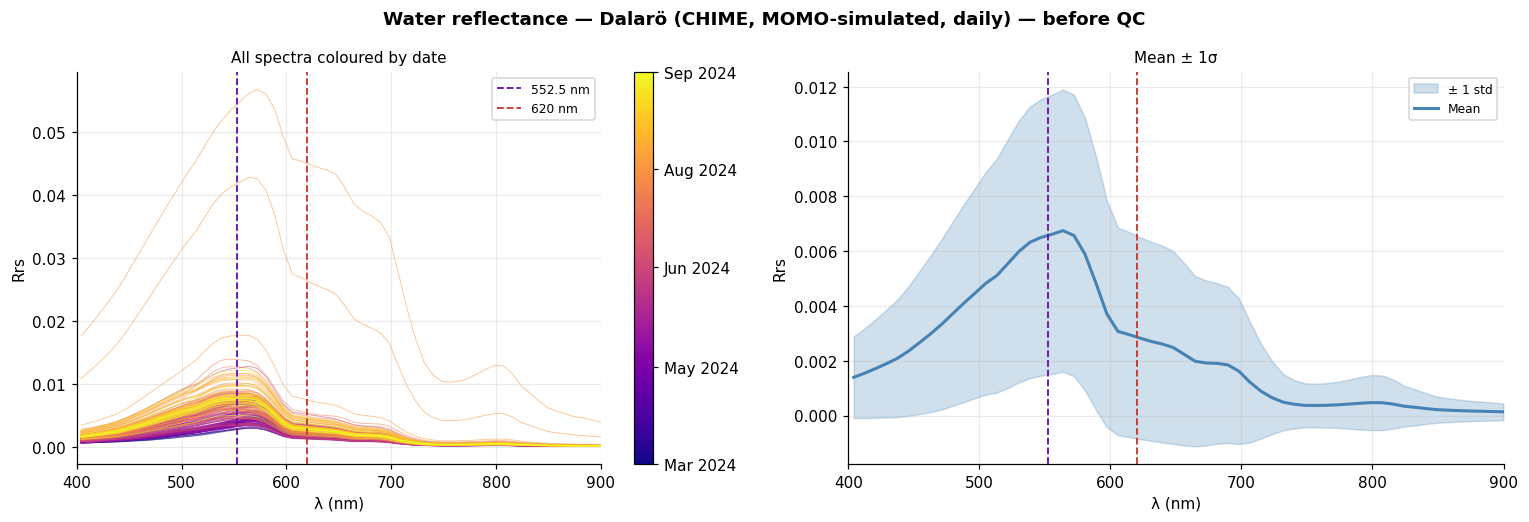

In [137]:
MARK = [(552.5, '552.5 nm', FEAT_COL['D2_552']), (620, '620 nm', FEAT_COL['D2_620'])]

def plot_reflectance(R, t, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    fig.suptitle(title, fontsize=12, fontweight='bold')
    ax = axes[0]; cmap = plt.cm.plasma
    norm_c = plt.Normalize(vmin=t.min().toordinal(), vmax=max(t.max().toordinal(), t.min().toordinal() + 1))
    m = (wl >= 400) & (wl <= 900)
    step = max(1, len(R) // 500)
    for i in range(0, len(R), step):
        ax.plot(wl[m], R[i, m], color=cmap(norm_c(t[i].toordinal())), lw=0.6, alpha=0.55)
    for lam, lbl, co in MARK:
        ax.axvline(lam, color=co, lw=1.2, ls='--', label=lbl)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm_c); sm.set_array([])
    cb = plt.colorbar(sm, ax=ax); ticks = pd.date_range(t.min(), t.max(), periods=5)
    cb.set_ticks([d.toordinal() for d in ticks]); cb.set_ticklabels([d.strftime('%b %Y') for d in ticks])
    ax.set_xlabel('λ (nm)'); ax.set_ylabel(DS['refl']); ax.set_xlim(400, 900)
    ax.set_title('All spectra coloured by date', fontsize=10); ax.legend(fontsize=8, loc='upper right')
    ax2 = axes[1]
    mu, sd = np.nanmean(R[:, m], axis=0), np.nanstd(R[:, m], axis=0)
    ax2.fill_between(wl[m], mu - sd, mu + sd, alpha=0.25, color='steelblue', label='± 1 std')
    ax2.plot(wl[m], mu, color='steelblue', lw=2, label='Mean')
    for lam, lbl, co in MARK:
        ax2.axvline(lam, color=co, lw=1.2, ls='--')
    ax2.set_xlabel('λ (nm)'); ax2.set_ylabel(DS['refl']); ax2.set_xlim(400, 900)
    ax2.set_title('Mean ± 1σ', fontsize=10); ax2.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(fname, dpi=150, bbox_inches='tight'); plt.show()

plot_reflectance(RHOW_all, t_all, f'Water reflectance — {STATION} — before QC', fig_path('0_reflectance_preQC'))

### 3.2 Quality control
| Test | Rejects |
|---|---|
| empty | no valid value in 400–700 nm |
| too bright | visible maximum ≥ `RHO_MAX` **and** spectrally flat, R(560)/R(440) < `FLAT_RATIO` (ice/snow) |
| negative | any negative value in 400–700 nm |
| NaN | NaN fraction > `NAN_MAX_FRAC` or a gap longer than `MAX_GAP_BANDS` bands (cannot be interpolated safely) |
| glint | NIR/green ratio ≥ `GLINT_RATIO` (only if 840–860 nm is covered) |
| time | outside `TIME_WINDOW` (only if timestamps carry a time) |
| irradiance | Ed(550) < `ED_MIN_FRAC` × daily maximum (only if Ed is available) |
| spike | fine sensors only (Δλ ≤ 5 nm): band-to-band spike in 450–720 nm, robust z-score > `SPIKE_Z` **and** relative size > `SPIKE_MIN`. Not applied to coarse sensors, where real narrow features (e.g. the red/fluorescence peak at ~690 nm) span only 2–3 bands |

Bright spectra that keep the water shape (green peak, red absorption) — e.g. surface scums or very high biomass —
are **kept** and listed as *high-reflectance* events instead of being rejected.

Short NaN gaps that pass the test are filled by linear interpolation along wavelength.

In [138]:
vis = (wl >= 400) & (wl <= 700)
Rv = RHOW_all[:, vis]

def longest_nan_run(row):
    best = run = 0
    for isn in np.isnan(row):
        run = run + 1 if isn else 0; best = max(best, run)
    return best

qc = pd.DataFrame(index=np.arange(len(t_all)))
qc['reject_empty']      = ~np.isfinite(Rv).any(axis=1)
# Ice/snow = bright AND spectrally flat (white). Bright spectra that keep the water
# shape (green peak, red absorption) — e.g. surface scums or very high biomass — are
# kept and flagged, not rejected.
vis_max = np.nan_to_num(np.nanmax(np.where(np.isfinite(Rv), Rv, -np.inf), axis=1), neginf=0)
r440 = np.nanmean(RHOW_all[:, (wl >= 430) & (wl <= 450)], axis=1)
r560 = np.nanmean(RHOW_all[:, (wl >= 550) & (wl <= 570)], axis=1)
with np.errstate(invalid='ignore', divide='ignore'):
    flat = (r560 / r440) < FLAT_RATIO
bright = vis_max >= RHO_MAX
qc['reject_too_bright']     = bright & flat            # ice / snow
qc['flag_high_reflectance'] = bright & ~flat           # kept: scum / very high biomass
qc['reject_negative']   = (np.nan_to_num(Rv, nan=0.0) < 0).any(axis=1)
qc['reject_nan']        = (np.isnan(Rv).mean(axis=1) > NAN_MAX_FRAC) | \
                          (np.array([longest_nan_run(r) for r in Rv]) > MAX_GAP_BANDS)
if wl[-1] >= 860:
    nir = np.nanmedian(RHOW_all[:, (wl >= 840) & (wl <= 860)], axis=1)
    grn = np.nanmax(RHOW_all[:, (wl >= 540) & (wl <= 590)], axis=1)
    qc['reject_glint'] = np.nan_to_num(nir / grn, nan=0.0) >= GLINT_RATIO
qc['reject_time'] = (~t_all.hour.isin(range(*TIME_WINDOW))) if (has_time and TIME_WINDOW) else False
if ED_all is not None:
    e = pd.Series(ED_all[:, np.argmin(np.abs(wl - 550))])
    qc['reject_irradiance'] = (e / e.groupby(t_all.normalize().values).transform('max')).values < ED_MIN_FRAC
# spectral spikes (fine sensors only): residual against a 3-band running median, relative to the local level
if delta_native <= 5.0:
    sp = (wl >= 450) & (wl <= 720)
    Rs = np.nan_to_num(RHOW_all[:, sp])
    mf = median_filter(Rs, size=(1, 3), mode='nearest')
    with np.errstate(invalid='ignore', divide='ignore'):
        spike_score = np.nanmax(np.abs(Rs - mf) / np.abs(mf), axis=1)
    med = np.nanmedian(spike_score); mad = 1.4826 * np.nanmedian(np.abs(spike_score - med))
    z = (spike_score - med) / mad if mad > 0 else np.zeros_like(spike_score)
    qc['reject_spike'] = (np.nan_to_num(z) > SPIKE_Z) & (spike_score > SPIKE_MIN)

rej = [c for c in qc if c.startswith('reject_')]
valid = ~qc[rej].any(axis=1).values
HIGH_REFL_DAYS = [str(d.date()) for d in t_all[qc['flag_high_reflectance'].values & valid]]
QC_COUNTS = {c.replace('reject_', ''): int(qc[c].sum()) for c in rej}
print('Rejected per test (a spectrum can fail several):', QC_COUNTS)
print(f'Valid spectra: {valid.sum()} / {len(valid)}')
if qc['flag_high_reflectance'].any():
    fl = qc['flag_high_reflectance'].values
    ratio = r560 / r440
    print('High reflectance with water-like shape, kept:',
          [f'{d.date()} (R560/R440 = {r:.1f})' for d, r in zip(t_all[fl & valid], ratio[fl & valid])] or 'none')
    if (fl & ~valid).any():
        print('  ⚠ also high reflectance, but rejected by another test (check whether it is a real event):',
              [str(d.date()) for d in t_all[fl & ~valid]])
for c in rej:
    if qc[c].any() and qc[c].sum() <= 10:
        print(f'  {c}: {[str(d.date()) for d in t_all[qc[c].values]]}')
if valid.sum() < 3:
    raise RuntimeError('Fewer than 3 spectra pass QC — check the units (refl) and the QC thresholds.')

RHOW  = RHOW_all[valid].copy()
times = t_all[valid]
dates = pd.Series(times.normalize())
# fill the remaining short NaN gaps along wavelength (only interior gaps ≤ MAX_GAP_BANDS reach this point)
for i, r in enumerate(RHOW):
    f = np.isfinite(r)
    if not f.all():
        RHOW[i] = np.interp(wl, wl[f], r[f])

Rejected per test (a spectrum can fail several): {'empty': 0, 'too_bright': 0, 'negative': 0, 'nan': 0, 'glint': 0, 'time': 0}
Valid spectra: 182 / 182
High reflectance with water-like shape, kept: ['2024-08-10 (R560/R440 = 2.1)', '2024-08-11 (R560/R440 = 2.5)']


### 3.3 Overview after QC

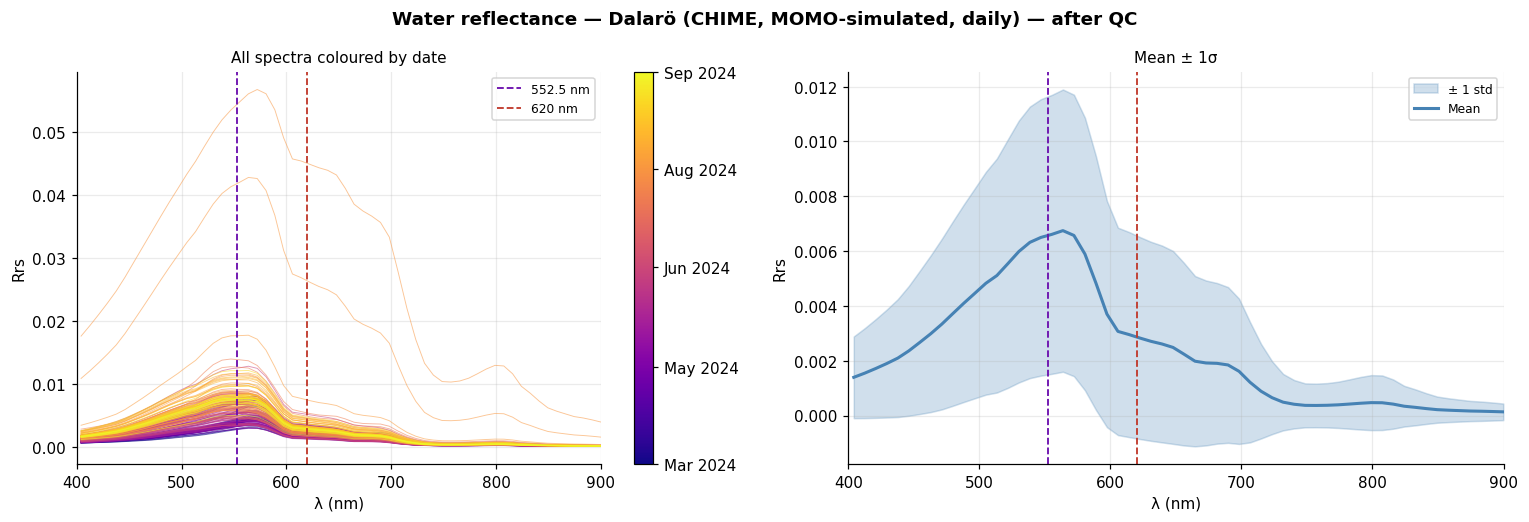

In [139]:
plot_reflectance(RHOW, times, f'Water reflectance — {STATION} — after QC', fig_path('1_reflectance_postQC'))

## 4. Processing scale
`cy.prepare_spectra` brings every spectrum to the analysis scale:
* **fine sensors** (Δλ ≤ 2.5 nm): Gaussian smoothing to `SMOOTH_FWHM` (added in quadrature to the native
  resolution), then linear resampling to a regular 2.5 nm grid;
* **coarse sensors** (Δλ > 2.5 nm, e.g. CHIME 8.4 nm): optional smoothing, **native bands kept** (no up-sampling).

The second derivative is always the explicit 3-point formula with the step of the grid it is computed on.

In [140]:
Rp, wlp, INFO = cy.prepare_spectra(RHOW, wl, smooth_fwhm=SMOOTH_FWHM, native_fwhm=DS['native_fwhm'])
COARSE = not INFO['regridded']
print(f'Native resolution     : {INFO["native_resolution"]:.2f} nm')
print(f'Effective resolution  : {INFO["effective_resolution"]:.2f} nm  (smoothing target: {SMOOTH_FWHM})')
print(f'Analysis grid         : {"native bands" if COARSE else "regular 2.5 nm"}, step {INFO["step"]:.2f} nm, '
      f'{len(wlp)} bands ({wlp[0]:.1f}–{wlp[-1]:.1f} nm)')
for lam in (cy.D2_WL_LEGACY, cy.D2_WL_PC):
    b = cy.bracketing_bands(wlp, lam)
    print(f'D²({lam}) interpolated between grid bands {b[0]:.1f} and {b[1]:.1f} nm')

Native resolution     : 8.40 nm
Effective resolution  : 8.40 nm  (smoothing target: None)
Analysis grid         : native bands, step 8.40 nm, 71 bands (404.2–992.2 nm)
D²(552.5) interpolated between grid bands 547.0 and 555.4 nm
D²(620.0) interpolated between grid bands 614.2 and 622.6 nm


## 5. Detection features and consistency checks
### 5.1 Features for every spectrum

In [141]:
FEATS, FINFO = cy.cyano_features(RHOW, wl, smooth_fwhm=SMOOTH_FWHM, native_fwhm=DS['native_fwhm'], norm_wl=NORM_WL)
spec = pd.DataFrame({'time': times, 'date': dates.values, **{f: np.asarray(FEATS[f], float) for f in FEATS_ALL}})
for f, (thr, sgn) in RULES.items():
    cyp = sgn * (spec[f] - thr) > 0
    print(f'  {FEAT_LABEL[f]:32s}  Cy+ (rule only, all spectra): {cyp.mean():6.1%}   NaN: {spec[f].isna().sum()}')

  D²(620) — phycocyanin trough      Cy+ (rule only, all spectra):  44.5%   NaN: 0
  D²(552.5) — legacy green peak     Cy+ (rule only, all spectra):  60.4%   NaN: 0


### 5.2 Formula consistency and band sensitivity
(a) `cy.second_derivative` must equal `phytospec.algorithms.compute_D2` with the same grid step, normalisation and
**no** smoothing — this guarantees that the raw and normalised cases use the same formula.
(b) Sign invariance under normalisation is tested in §11.
(c) Coarse grids only: the target wavelength falls between two bands; if the two bands disagree in sign, the
interpolated value depends on the exact target wavelength.

In [142]:
# (a) same formula as phytospec (regular grids only: compute_D2 assumes a constant step)
FORMULA_DIFF = np.nan
if np.ptp(np.diff(wlp)) / np.median(np.diff(wlp)) < 1e-3:
    nw = cy.nearest_band(wlp, 442.5)          # compute_D2 normalises at the nearest grid point
    a = np.array([alg.compute_D2(r, wlp, norm_wl=nw, delta=INFO['step'], n_smooth=0) for r in Rp[:200]])
    b = cy.second_derivative(Rp[:200], wlp, norm_wl=nw)
    ok = np.isfinite(a) & np.isfinite(b)
    FORMULA_DIFF = float(np.max(np.abs(a[ok] - b[ok])) / np.max(np.abs(a[ok])))
    print(f'(a) max |cyano − phytospec.compute_D2| / max|D²| = {FORMULA_DIFF:.1e}  '
          + ('OK (numerical precision)' if FORMULA_DIFF < 1e-9 else '⚠ the two implementations differ'))
else:
    print('(a) irregular grid: comparison with compute_D2 (constant step) not applicable')

# (c) band sensitivity on coarse grids
BAND_SENS = {}
if COARSE:
    D = cy.second_derivative(Rp, wlp)
    for f in ('D2_552', 'D2_620'):
        b0, b1 = cy.bracketing_bands(wlp, FEAT_WL[f])
        s0 = np.sign(D[:, np.argmin(np.abs(wlp - b0))]); s1 = np.sign(D[:, np.argmin(np.abs(wlp - b1))])
        BAND_SENS[f] = float(np.mean(s0 != s1))
        thr, sgn = RULES[f]
        print(f'(c) {f}: bands {b0:.1f}/{b1:.1f} nm disagree in sign for {BAND_SENS[f]:.0%} of spectra '
              f'(Cy+ at {b0:.1f}: {np.mean(sgn * s0 > 0):.0%}, at {b1:.1f}: {np.mean(sgn * s1 > 0):.0%})')
else:
    print('(c) fine grid: not applicable')

(a) max |cyano − phytospec.compute_D2| / max|D²| = 3.7e-14  OK (numerical precision)
(c) D2_552: bands 547.0/555.4 nm disagree in sign for 87% of spectra (Cy+ at 547.0: 80%, at 555.4: 23%)
(c) D2_620: bands 614.2/622.6 nm disagree in sign for 68% of spectra (Cy+ at 614.2: 6%, at 622.6: 74%)


## 6. Daily values, noise and three-class classification
* **Several spectra per day** (WISP): daily median; noise = within-day inter-quartile range.
* **One spectrum per day**: noise from the high-frequency residual of the spectrum (750–800 nm if covered),
  propagated through the full chain by Monte-Carlo.
* **Simulated spectra** (`USE_SNR = False`): no noise model — classes follow the rule only.

A day is **undetermined** when |value − threshold| / noise < `SNR_MIN`.

In [143]:
rng = np.random.default_rng(RNG_SEED)
g = spec.groupby('date')
day = pd.DataFrame({'n': g.size()})
for f in FEATS_ALL:
    day[f] = g[f].median()
    day[f + '_iqr'] = g[f].quantile(0.75) - g[f].quantile(0.25)
MULTI = (day.n >= 3).mean() > 0.5

def mc_noise(r):
    nirw = (wl >= 750) & (wl <= 800) if wl[-1] >= 800 else (wl >= 400) & (wl <= 700)
    resid = r[nirw] - gaussian_filter1d(r, max(1.0, 5.0 / delta_native), mode='nearest')[nirw]
    sims = r[None, :] + rng.normal(0, np.std(resid), (N_MC, r.size))
    fs, _ = cy.cyano_features(sims, wl, smooth_fwhm=SMOOTH_FWHM, native_fwhm=DS['native_fwhm'], norm_wl=NORM_WL)
    return {f: np.nanstd(fs[f]) for f in FEATS_ALL}

if not USE_SNR:
    NOISE_METHOD = 'none (simulated spectra — rule only)'
    for f in FEATS_ALL:
        day[f + '_noise'] = np.nan
elif MULTI:
    NOISE_METHOD = 'within-day IQR'
    for f in FEATS_ALL:
        day[f + '_noise'] = day[f + '_iqr'].where(day.n >= 3)
else:
    NOISE_METHOD = f'Monte-Carlo ({N_MC} realisations)'
    first = spec.drop_duplicates('date').index
    nz = pd.DataFrame([mc_noise(RHOW[i]) for i in first], index=pd.DatetimeIndex(spec.loc[first, 'date'].values))
    for f in FEATS_ALL:
        day[f + '_noise'] = nz[f] / np.sqrt(day.n)

def classify_feature(values, noise, thr, sgn):
    cls = np.where(sgn * (values - thr) > 0, 'Cy+', 'Cy-').astype(object)
    with np.errstate(divide='ignore', invalid='ignore'):
        snr = np.abs(values - thr) / noise
    if USE_SNR:
        cls[~(snr >= SNR_MIN)] = 'undetermined'          # also when the noise is unknown
    cls[~np.isfinite(values)] = 'undetermined'
    return cls, snr

for f, (thr, sgn) in RULES.items():
    day[f + '_class'], day[f + '_snr'] = classify_feature(day[f].values, day[f + '_noise'].values, thr, sgn)

def rep_index(d, feat=MAIN_FEATURE):
    """Row of the spectrum of day d whose feature value is closest to the daily median (representative spectrum)."""
    ii = np.where(dates.values == np.datetime64(pd.Timestamp(d)))[0]
    dif = np.abs(spec[feat].values[ii] - day.loc[d, feat])
    return int(ii[0] if np.all(np.isnan(dif)) else ii[np.nanargmin(dif)])

print(f'Noise: {NOISE_METHOD} | days: {len(day)} | spectra per day (median): {day.n.median():.0f}\n')
print(pd.DataFrame({FEAT_LABEL[f]: day[f + '_class'].value_counts() for f in RULES}).fillna(0).astype(int).to_string())

Noise: none (simulated spectra — rule only) | days: 182 | spectra per day (median): 1

     D²(620) — phycocyanin trough  D²(552.5) — legacy green peak
Cy+                            81                            110
Cy-                           101                             72


## 7. In-situ taxonomy and match-ups (optional)
Cyanobacteria share = cyanobacteria biomass / total phytoplankton biomass. A sample is **cyano-dominated** when the
share is ≥ `CY_DOM_FRAC`. Each sample is matched to the closest spectral day within `match_days`. If several samples
fall on the same spectral day, only the closest one is kept, so a spectrum is never counted twice (no pseudo-replication).

In [144]:
def _to_datetime(s, fmt=None):
    if pd.api.types.is_datetime64_any_dtype(s):
        return pd.to_datetime(s)
    return pd.to_datetime(s.astype(str).str.strip(), errors='coerce', format=fmt)

def load_insitu(s):
    p = Path(s['file'])
    if not p.exists():
        print(f'⚠ in-situ file not found: {p} → no validation'); return None
    if s['layout'] == 'wide':
        d = pd.read_excel(p, sheet_name=s.get('sheet', 0), header=s.get('header', 0))
        miss = [c for c in (s['date_col'], s['total_col'], s['cyano_col']) if c not in d.columns]
        if miss:
            raise KeyError(f'in-situ columns not found: {miss}. Available: {list(d.columns)[:20]} …')
        out = pd.DataFrame({'date': _to_datetime(d[s['date_col']], s.get('date_format')),
                            'total': pd.to_numeric(d[s['total_col']], errors='coerce'),
                            'cyano': pd.to_numeric(d[s['cyano_col']], errors='coerce')})
        if s.get('cyano_nan_as_zero'):
            out['cyano'] = out['cyano'].where(out['total'].isna(), out['cyano'].fillna(0))
    elif s['layout'] == 'long':
        d = pd.read_excel(p, sheet_name=s.get('sheet', 0))
        miss = [c for c in (s['date_col'], s['group_col'], s['value_col'], s.get('site_col')) if c and c not in d.columns]
        if miss:
            raise KeyError(f'in-situ columns not found: {miss}. Available: {list(d.columns)[:20]} …')
        if s.get('site_col'):                                   # keep the station matching the radiometer
            d = d[d[s['site_col']].astype(str) == str(s['site'])]
        d = d[~d[s['group_col']].isin(s.get('exclude_groups', []))].copy()
        d['date'] = _to_datetime(d[s['date_col']], s.get('date_format'))
        d['v'] = pd.to_numeric(d[s['value_col']], errors='coerce')
        out = pd.DataFrame({'total': d.groupby('date')['v'].sum(min_count=1),
                            'cyano': d[d[s['group_col']].isin(s['cyano_groups'])].groupby('date')['v'].sum()})
        out = out.rename_axis('date').reset_index()
        out['cyano'] = out['cyano'].fillna(0)
    else:
        raise ValueError(f'unknown in-situ layout {s["layout"]}')
    n_raw = len(out)
    out = out.dropna(subset=['date', 'total', 'cyano'])
    out = out[out['total'] > 0]
    out = out.groupby(out['date'].dt.normalize()).mean(numeric_only=True)     # replicate samples → daily mean
    out.index.name = 'date'
    out['cy_frac'] = out['cyano'] / out['total']
    if (out['cy_frac'] > 1.0001).any():
        print(f'⚠ {int((out["cy_frac"] > 1.0001).sum())} samples with cyanobacteria > total biomass — check units/columns')
    out['cy_dom'] = out['cy_frac'] >= CY_DOM_FRAC
    print(f'In-situ rows read: {n_raw}, usable sampling days: {len(out)}')
    return out

INS, MU, N_MU_DUP = None, None, 0
if DS['insitu'] is not None:
    INS = load_insitu(INSITU[DS['insitu']])
if INS is not None and len(INS):
    dd = pd.DatetimeIndex(day.index)
    lag = np.abs((INS.index.values.astype('datetime64[D]')[:, None]
                  - dd.values.astype('datetime64[D]')[None, :]).astype(int))
    j = lag.argmin(axis=1); lmin = lag[np.arange(len(j)), j]
    ok = lmin <= DS['match_days']
    MU = INS[ok].assign(spec_day=dd[j[ok]], lag_days=lmin[ok]).reset_index()
    n0 = len(MU)
    MU = (MU.sort_values(['spec_day', 'lag_days', 'date']).drop_duplicates('spec_day', keep='first')
            .sort_values('date').reset_index(drop=True))
    N_MU_DUP = n0 - len(MU)
    MU = MU.join(day, on='spec_day')
    MU['cy_dom'] = MU['cy_dom'].astype(bool)
    in_period = INS[(INS.index >= dd.min() - pd.Timedelta(days=DS['match_days'])) &
                    (INS.index <= dd.max() + pd.Timedelta(days=DS['match_days']))]
    print(f'In-situ samples: {len(INS)} ({INS.index.min().date()} → {INS.index.max().date()}), '
          f'{len(in_period)} inside the spectral period, {len(MU)} matched (±{DS["match_days"]} d)'
          + (f', {N_MU_DUP} dropped (same spectral day as a closer sample)' if N_MU_DUP else ''))
    if len(MU):
        print(f'Matched: {int(MU.cy_dom.sum())} cyano-dominated, {int((~MU.cy_dom).sum())} not dominated '
              f'(threshold {CY_DOM_FRAC:.0%})')
        if MU.cy_dom.all() or (~MU.cy_dom).all():
            print(f'⚠ All match-ups are {"cyano-dominated" if MU.cy_dom.all() else "not dominated"} '
                  f'(in-situ share {MU.cy_frac.min():.0%}–{MU.cy_frac.max():.0%}): '
                  + ('only sensitivity (POD) can be measured; false-positive rate, FAR, KSS and AUC are undefined. '
                     if MU.cy_dom.all() else 'only the false-positive rate can be measured. ')
                  + 'Spearman ρ against the continuous share remains informative.')
    else:
        MU = None
        print('No match-ups within the matching window → validation skipped.')

In-situ rows read: 27, usable sampling days: 27
In-situ samples: 27 (2024-03-12 → 2024-09-24), 26 inside the spectral period, 26 matched (±0 d)
Matched: 13 cyano-dominated, 13 not dominated (threshold 30%)


## 8. Time series

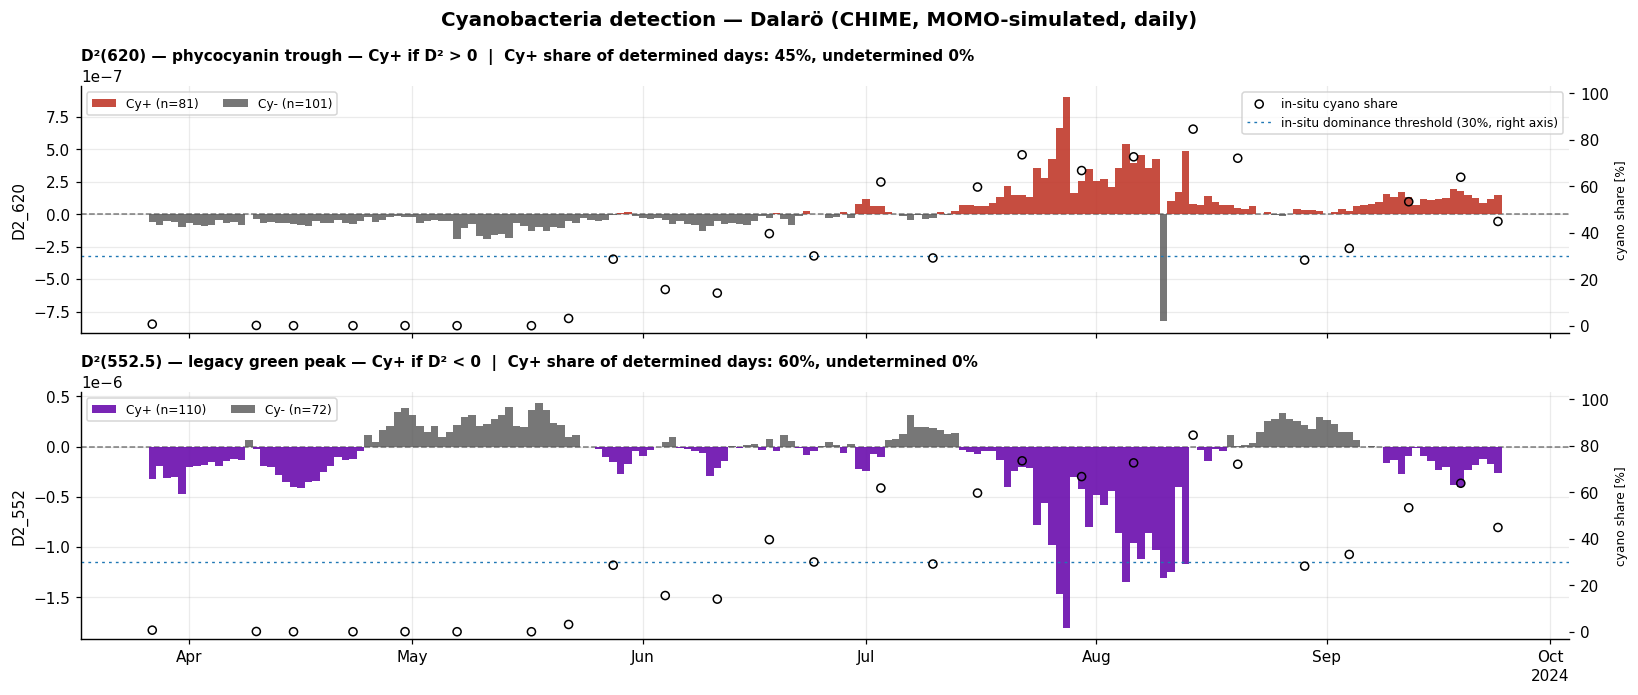

In [145]:
CLS_STYLE = {'Cy+': dict(alpha=0.9), 'Cy-': dict(color='#555555', alpha=0.8),
             'undetermined': dict(color='#dddddd', hatch='///', edgecolor='#999999')}
fig, axes = plt.subplots(len(FEATS_ALL), 1, figsize=(15, 3.2 * len(FEATS_ALL)), sharex=True, squeeze=False)
x = pd.DatetimeIndex(day.index)
w = 1.0 if (MULTI or len(day) > 150) else 2.5
for ax, f in zip(axes[:, 0], FEATS_ALL):
    thr, sgn = RULES[f]
    for c in ['Cy+', 'Cy-', 'undetermined']:
        m = (day[f + '_class'] == c).values
        if not m.any():
            continue
        kw = dict(CLS_STYLE[c]); kw.setdefault('color', FEAT_COL[f])
        ax.bar(x[m], day[f].values[m] - thr, bottom=thr, width=w, label=f'{c} (n={m.sum()})', zorder=3, **kw)
    ax.axhline(thr, color='k', lw=1, ls='--', alpha=0.5)
    det = day[f + '_class'] != 'undetermined'
    share = (day.loc[det, f + '_class'] == 'Cy+').mean() if det.any() else np.nan
    ax.set_title(f'{FEAT_LABEL[f]} — Cy+ if {"D² < 0" if sgn < 0 else "D² > 0"}  |  Cy+ share of determined days: '
                 f'{share:.0%}, undetermined {(~det).mean():.0%}', loc='left', fontsize=10, fontweight='bold')
    ax.set_ylabel(f)
    if MU is not None:
        ax2 = ax.twinx()
        ax2.scatter(MU.date, 100 * MU.cy_frac, s=28, facecolors='none', edgecolors='k', lw=1, zorder=6,
                    label='in-situ cyano share')
        ax2.axhline(100 * CY_DOM_FRAC, color='#1f77b4', lw=0.9, ls=(0, (2, 3)),
                    label=f'in-situ dominance threshold ({CY_DOM_FRAC:.0%}, right axis)')
        ax2.set_ylim(-3, 103); ax2.set_ylabel('cyano share [%]', fontsize=8); ax2.grid(False)
        if f == FEATS_ALL[0]:
            ax2.legend(fontsize=8, loc='upper right')
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=8, loc='upper left', ncol=3, framealpha=0.8)
loc = mdates.AutoDateLocator()
axes[-1, 0].xaxis.set_major_locator(loc); axes[-1, 0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
fig.suptitle(f'Cyanobacteria detection — {STATION}', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.savefig(fig_path('2_timeseries'), dpi=150, bbox_inches='tight'); plt.show()

## 9. Monthly summary

In [146]:
month = pd.DatetimeIndex(day.index).to_period('M')
mon = pd.DataFrame({'days': day.groupby(month).size()})
for f in RULES:
    grp = day.groupby(month)[f + '_class']
    mon[f'{f} Cy+'] = grp.apply(lambda s: int((s == 'Cy+').sum()))
    mon[f'{f} und.'] = grp.apply(lambda s: int((s == 'undetermined').sum()))
if INS is not None:
    im = INS.groupby(INS.index.to_period('M'))
    mon['in-situ n'] = im.size().reindex(mon.index).fillna(0).astype(int)
    mon['in-situ cyano share (median)'] = im.cy_frac.median().reindex(mon.index).map(
        lambda v: f'{v:.0%}' if pd.notna(v) else '—')
mon.index.name = 'month'
display(mon)

,days,D2_620 Cy+,D2_620 und.,D2_552 Cy+,D2_552 und.,in-situ n,in-situ cyano share (median)
month,,,,,,,
2024-03,5,0,0,5,0,2,1%
2024-04,30,0,0,23,0,4,0%
2024-05,31,2,0,7,0,4,2%
2024-06,30,5,0,18,0,4,23%
2024-07,31,24,0,21,0,5,62%
2024-08,31,26,0,18,0,4,72%
2024-09,24,24,0,18,0,4,49%


Indirect check: historical in-situ climatology vs spectral classification

In [147]:
# Indirect check: historical in-situ climatology (all years) vs WISP classification in the spectral period
if INS is not None:
    m_ins = INS.groupby(INS.index.month)
    clim = pd.DataFrame({'in-situ samples (all years)': m_ins.size(),
                         'median cyano share': m_ins['cy_frac'].median().map('{:.0%}'.format),
                         'samples < 30 %': m_ins['cy_dom'].apply(lambda s: f'{(~s).sum()} of {len(s)}')})
    m_day = day.groupby(pd.DatetimeIndex(day.index).month)[MAIN_FEATURE + '_class']
    clim['spectral days'] = m_day.size()
    clim['Cy+ share of spectral days'] = m_day.apply(lambda s: f'{(s == "Cy+").mean():.0%}')
    clim.index.name = 'month'
    display(clim.dropna(subset=['spectral days']))

,in-situ samples (all years),median cyano share,samples < 30 %,spectral days,Cy+ share of spectral days
month,,,,,
3,2,1%,2 of 2,5,0%
4,4,0%,4 of 4,30,0%
5,4,2%,4 of 4,31,6%
6,4,23%,2 of 4,30,17%
7,5,62%,1 of 5,31,77%
8,4,72%,1 of 4,31,84%
9,4,49%,0 of 4,24,100%


## 10. Validation against in-situ taxonomy
For each D² feature, against in-situ cyano-dominance (share ≥ `CY_DOM_FRAC`):

| Metric | Definition | Ideal |
|---|---|---|
| TP / FN / FP / TN | confusion matrix of the rule; undetermined days are reported separately and excluded | — |
| coverage | share of match-ups that are not undetermined | 1 |
| sensitivity (POD) | TP / (TP + FN) | 1 |
| FPR = POFD | FP / (FP + TN) — false-positive rate (probability of false detection) | 0 |
| FAR | FP / (TP + FP) — false-alarm *ratio* (share of Cy+ detections that are wrong) | 0 |
| CSI | TP / (TP + FP + FN) — critical success index | 1 |
| KSS | POD − POFD — Hanssen–Kuipers skill score | 1 (0 = no skill) |
| AUC | probability that a dominated sample has a higher direction-adjusted D² than a non-dominated one (continuous value; direction fixed a priori by the rule, never chosen from the data) | 1 (0.5 = no skill) |
| Spearman ρ | rank correlation of the direction-adjusted D² with the in-situ cyano share | 1 |

Confidence intervals: Wilson score interval for POD and FPR; stratified bootstrap for AUC.
The rules have a fixed physical threshold (0), so no parameter is fitted on the evaluation data.

,n (dominated),TP / FN / FP / TN,undetermined (dom / not),coverage,POD [95% CI],FPR = POFD [95% CI],FAR,CSI,KSS,AUC [95% CI],Spearman ρ (p)
feature,,,,,,,,,,,
D²(620) — phycocyanin trough,26 (13),12 / 1 / 1 / 12,0 / 0,100%,92% [67%–99%],8% [1%–33%],0.08,0.86,0.85,0.97 [0.89–1.00],0.90 (3e-10)
D²(552.5) — legacy green peak,26 (13),10 / 3 / 6 / 7,0 / 0,100%,77% [50%–92%],46% [23%–71%],0.38,0.53,0.31,0.69 [0.47–0.88],0.34 (0.09)


⚠ Simulated spectra: the reflectance was simulated from the measured biogeochemistry, so agreement with the in-situ taxonomy is partly by construction. These scores are not an independent validation.
⚠ n = 26 match-ups: confidence intervals are wide; differences between features within the intervals are not significant. Samples from one time series are autocorrelated, so the intervals are if anything optimistic.


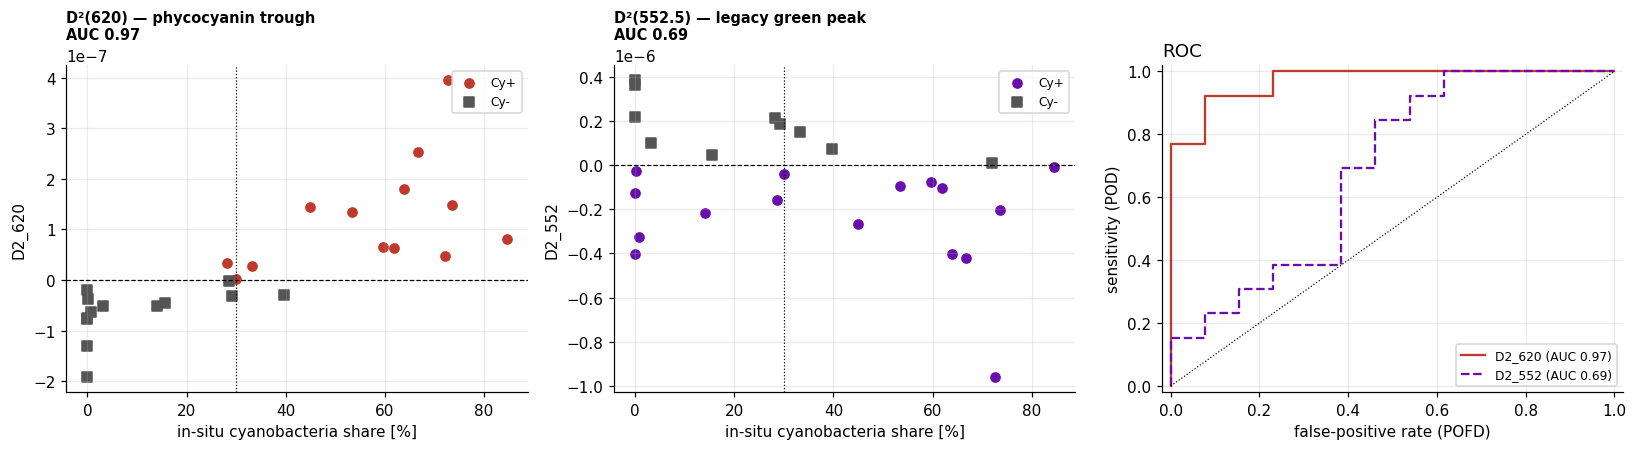

In [148]:
Z_CI = float(normal_dist.ppf(0.5 + CI_LEVEL / 2))

def wilson(k, n, z=Z_CI):
    """Wilson score interval for a binomial proportion k/n."""
    if n == 0:
        return np.nan, np.nan
    p = k / n; den = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return max(0.0, c - h), min(1.0, c + h)

def _auc_rank(s, p):
    n1, n0 = int(p.sum()), int((~p).sum())
    if n1 == 0 or n0 == 0:
        return np.nan
    r = rankdata(s)                                         # average ranks for ties (Mann–Whitney U / n1·n0)
    return float((r[p].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

def auc(score, pos):
    s, p = np.asarray(score, float), np.asarray(pos, bool)
    ok = np.isfinite(s)
    return _auc_rank(s[ok], p[ok])

def auc_ci(score, pos, n_boot=N_BOOT, level=CI_LEVEL, seed=RNG_SEED):
    """Stratified bootstrap (positives and negatives resampled separately) percentile interval of the AUC."""
    s, p = np.asarray(score, float), np.asarray(pos, bool)
    ok = np.isfinite(s); s, p = s[ok], p[ok]
    sp, sn = s[p], s[~p]
    if sp.size < 2 or sn.size < 2:
        return np.nan, np.nan
    rg = np.random.default_rng(seed)
    lab = np.r_[np.ones(sp.size, bool), np.zeros(sn.size, bool)]
    vals = np.array([_auc_rank(np.r_[rg.choice(sp, sp.size), rg.choice(sn, sn.size)], lab) for _ in range(n_boot)])
    return tuple(np.nanpercentile(vals, [50 * (1 - level), 50 * (1 + level)]))

def confusion_scores(cls, dom):
    cls = np.asarray(cls, dtype=object); dom = np.asarray(dom, bool)
    det = cls != 'undetermined'; pos = cls == 'Cy+'
    TP, FN = int((pos & dom).sum()), int((det & ~pos & dom).sum())
    FP, TN = int((pos & ~dom).sum()), int((det & ~pos & ~dom).sum())
    pod = TP / (TP + FN) if TP + FN else np.nan
    pofd = FP / (FP + TN) if FP + TN else np.nan
    return {'TP': TP, 'FN': FN, 'FP': FP, 'TN': TN,
            'und_dom': int((~det & dom).sum()), 'und_not': int((~det & ~dom).sum()),
            'coverage': float(det.mean()) if cls.size else np.nan,
            'POD': pod, 'POD_lo': wilson(TP, TP + FN)[0], 'POD_hi': wilson(TP, TP + FN)[1],
            'POFD': pofd, 'POFD_lo': wilson(FP, FP + TN)[0], 'POFD_hi': wilson(FP, FP + TN)[1],
            'FAR': FP / (TP + FP) if TP + FP else np.nan,
            'CSI': TP / (TP + FP + FN) if TP + FP + FN else np.nan,
            'KSS': pod - pofd}

def roc_points(score, pos):
    s, p = np.asarray(score, float), np.asarray(pos, bool)
    ok = np.isfinite(s); s, p = s[ok], p[ok]
    if p.sum() == 0 or (~p).sum() == 0:
        return None
    t = np.unique(s)[::-1]
    pred = s[None, :] >= t[:, None]
    return np.r_[0, pred[:, ~p].mean(axis=1)], np.r_[0, pred[:, p].mean(axis=1)]

def _fmt_ci(v, lo, hi, pct):
    if not np.isfinite(v):
        return '—'
    if pct:
        return f'{v:.0%} [{lo:.0%}–{hi:.0%}]' if np.isfinite(lo) else f'{v:.0%}'
    return f'{v:.2f} [{lo:.2f}–{hi:.2f}]' if np.isfinite(lo) else f'{v:.2f}'

def _fmt(v, nd=2):
    return '—' if not np.isfinite(v) else f'{v:.{nd}f}'

VAL_NUM, VAL = None, None
if MU is not None:
    dom = MU.cy_dom.values
    rows, disp = [], []
    for f in FEATS_ALL:
        thr, sgn = RULES[f]
        score = sgn * MU[f].values.astype(float)
        fin = np.isfinite(score)
        rho, pval = spearmanr(score[fin], MU.cy_frac.values[fin]) if fin.sum() >= 3 else (np.nan, np.nan)
        a, (alo, ahi) = auc(score, dom), auc_ci(score, dom)
        cs = confusion_scores(MU[f + '_class'].values, dom)
        rows.append({'feature': f, 'n': len(MU), 'dominated': int(dom.sum()),
                     **cs, 'AUC': a, 'AUC_lo': alo, 'AUC_hi': ahi, 'spearman_rho': rho, 'spearman_p': pval})
        disp.append({'feature': FEAT_LABEL[f],
                     'n (dominated)': f'{len(MU)} ({int(dom.sum())})',
                     'TP / FN / FP / TN': f'{cs["TP"]} / {cs["FN"]} / {cs["FP"]} / {cs["TN"]}',
                     'undetermined (dom / not)': f'{cs["und_dom"]} / {cs["und_not"]}',
                     'coverage': f'{cs["coverage"]:.0%}',
                     f'POD [{CI_LEVEL:.0%} CI]': _fmt_ci(cs['POD'], cs['POD_lo'], cs['POD_hi'], True),
                     f'FPR = POFD [{CI_LEVEL:.0%} CI]': _fmt_ci(cs['POFD'], cs['POFD_lo'], cs['POFD_hi'], True),
                     'FAR': _fmt(cs['FAR']), 'CSI': _fmt(cs['CSI']), 'KSS': _fmt(cs['KSS']),
                     f'AUC [{CI_LEVEL:.0%} CI]': _fmt_ci(a, alo, ahi, False),
                     'Spearman ρ (p)': '—' if not np.isfinite(rho) else f'{rho:.2f} ({pval:.1g})'})
    VAL_NUM = pd.DataFrame(rows).set_index('feature')
    VAL = pd.DataFrame(disp).set_index('feature')
    display(VAL)

    if DS['simulated']:
        print('⚠ Simulated spectra: the reflectance was simulated from the measured biogeochemistry, so agreement with '
              'the in-situ taxonomy is partly by construction. These scores are not an independent validation.')
    if len(MU) < 30:
        print(f'⚠ n = {len(MU)} match-ups: confidence intervals are wide; differences between features within the '
              'intervals are not significant. Samples from one time series are autocorrelated, so the intervals are '
              'if anything optimistic.')

    fig, axes = plt.subplots(1, len(FEATS_ALL) + 1, figsize=(5 * (len(FEATS_ALL) + 1), 4.2), squeeze=False)
    for ax, f in zip(axes[0], FEATS_ALL):
        thr, sgn = RULES[f]
        cls = MU[f + '_class']
        for c, mk, col in [('Cy+', 'o', FEAT_COL[f]), ('Cy-', 's', '#555555'), ('undetermined', 'x', '#999999')]:
            m = (cls == c).values
            if m.any():
                ax.scatter(100 * MU.cy_frac[m], MU[f][m], marker=mk, color=col, s=36, label=c)
        ax.axhline(thr, color='k', ls='--', lw=0.8)
        ax.axvline(100 * CY_DOM_FRAC, color='k', ls=':', lw=0.8)
        ax.set_xlabel('in-situ cyanobacteria share [%]'); ax.set_ylabel(f)
        ax.ticklabel_format(axis='y', style='sci', scilimits=(-3, 3))
        ax.set_title(f'{FEAT_LABEL[f]}\nAUC {_fmt(VAL_NUM.loc[f, "AUC"])}', fontsize=9.5, loc='left', fontweight='bold')
        if ax.get_legend_handles_labels()[0]:
            ax.legend(fontsize=8)
    ax = axes[0, -1]
    if dom.all() or (~dom).all():
        ax.text(0.5, 0.5, 'ROC undefined:\nonly one in-situ class', ha='center', va='center',
                transform=ax.transAxes, fontsize=10, color='0.4')
    for f in FEATS_ALL:
        pts = roc_points(RULES[f][1] * MU[f].values.astype(float), dom)
        if pts is not None:
            ax.plot(pts[0], pts[1], '-' if f == MAIN_FEATURE else '--', drawstyle='steps-post', color=FEAT_COL[f],
                    label=f'{f} (AUC {_fmt(VAL_NUM.loc[f, "AUC"])})')
    ax.plot([0, 1], [0, 1], 'k:', lw=0.8)
    ax.set_xlabel('false-positive rate (POFD)'); ax.set_ylabel('sensitivity (POD)'); ax.set_title('ROC', loc='left')
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=8, loc='lower right')
    plt.tight_layout(); plt.savefig(fig_path('3_validation'), dpi=150, bbox_inches='tight'); plt.show()
else:
    print('No in-situ match-ups → validation skipped.')

## 11. Normalisation sensitivity
D² is computed on the same processed spectra (§4) with the same formula for every normalisation; only the
normalisation changes. Dividing a spectrum by one **positive** number cannot change the sign of D², so a sign-based
rule must give identical classes. The only way the sign can differ is ρ(λn) ≤ 0; such spectra are rejected (NaN)
and counted rather than silently flipped. Normalisation **does** change the amplitude of D² and can change the ranking
between days — this matters for continuous scores (AUC) and for any non-zero threshold.

### 11.1 Summary table (both D² features)

In [149]:
NORM_OK = [c for c in NORMS if c[1] is None or (wlp[0] <= c[1] <= wlp[-1])]
NORM_LABEL = {k: lbl for k, _, lbl, _ in NORM_OK}
skipped = [lbl for _, _, lbl, _ in NORMS if lbl not in NORM_LABEL.values()]
if skipped:
    print('Skipped (wavelength outside the analysis grid):', skipped)

FEAT_N, D2CUBE = {}, {}
for key, nw, lbl, col in NORM_OK:
    FEAT_N[key] = pd.DataFrame({f: np.asarray(cy.d2_at(Rp, wlp, FEAT_WL[f], norm_wl=nw), float)
                                for f in ('D2_620', 'D2_552')})
    D2CUBE[key] = cy.second_derivative(Rp, wlp, norm_wl=nw)      # same normalisation as d2_at (interpolated ρ(λn))
DM = {k: v.assign(date=dates.values).groupby('date').median() for k, v in FEAT_N.items()}   # daily medians

# same pipeline as the detection: the raw values must equal the features of §5 (when NORM_WL is None)
if NORM_WL is None:
    for f in ('D2_620', 'D2_552'):
        same = np.allclose(FEAT_N['raw'][f].values, spec[f].values, rtol=1e-6, atol=1e-12, equal_nan=True)
        print(f'{f}: §11 raw values identical to the §5 detection features: {same}')

rows = []
for f in ('D2_620', 'D2_552'):
    sgn = RULES[f][1]
    ref, refd = FEAT_N['raw'][f].values, DM['raw'][f]
    for key, nw, lbl, col in NORM_OK:
        v, vd = FEAT_N[key][f].values, DM[key][f]
        fin = np.isfinite(v) & np.isfinite(ref)
        fd = np.isfinite(vd.values)
        rn = np.array([np.interp(nw, wlp, r_) for r_ in Rp]) if nw is not None else None   # ρ(λn) as used by cy
        r = {'feature': f, 'normalisation': lbl,
             'median ρ(λn)': np.nan if rn is None else float(np.nanmedian(rn)),
             'spectra with ρ(λn) ≤ 0': 0 if rn is None else int((rn <= 0).sum()),
             'lost vs raw (NaN)': int((~np.isfinite(v) & np.isfinite(ref)).sum()),
             'sign agreement with raw [%]': 100 * float(np.mean(np.sign(v[fin]) == np.sign(ref[fin]))) if fin.any() else np.nan,
             'sign flips': int((np.sign(v[fin]) != np.sign(ref[fin])).sum()),
             'Cy+ days [%]': 100 * float(np.mean(sgn * vd.values[fd] > 0)) if fd.any() else np.nan,
             'median |D²| (daily)': float(np.nanmedian(np.abs(vd.values))),
             'Spearman ρ vs raw (daily)': float(spearmanr(vd, refd, nan_policy='omit')[0]) if fd.sum() >= 3 else np.nan}
        if MU is not None:
            r['AUC'] = auc(sgn * vd.reindex(MU.spec_day).values, MU.cy_dom.values)
        rows.append(r)
NORM_TAB = pd.DataFrame(rows)
SIGN_OK = bool(NORM_TAB['sign flips'].sum() == 0)
_fmt_norm = {'median ρ(λn)': '{:.4f}', 'sign agreement with raw [%]': '{:.1f}', 'Cy+ days [%]': '{:.1f}',
             'median |D²| (daily)': '{:.3e}', 'Spearman ρ vs raw (daily)': '{:.3f}', 'AUC': '{:.2f}'}
try:
    display(NORM_TAB.style.format({k: v for k, v in _fmt_norm.items() if k in NORM_TAB}, na_rep='—'))
except ImportError:                                   # pandas Styler needs jinja2
    display(NORM_TAB)
print('Sign of D² identical under every normalisation.' if SIGN_OK else
      '⚠ The sign differs for some spectra — see "sign flips" and "spectra with ρ(λn) ≤ 0".')

D2_620: §11 raw values identical to the §5 detection features: True
D2_552: §11 raw values identical to the §5 detection features: True


,feature,normalisation,median ρ(λn),spectra with ρ(λn) ≤ 0,lost vs raw (NaN),sign agreement with raw [%],sign flips,Cy+ days [%],median |D²| (daily),Spearman ρ vs raw (daily),AUC
0,D2_620,No normalisation,—,0,0,100.0,0,44.5,6.860e-08,1.000,0.97
1,D2_620,Norm 442.5 nm,0.0020,0,0,100.0,0,44.5,4.253e-05,0.969,0.96
2,D2_620,Norm 620 nm (Lubac 2008),0.0024,0,0,100.0,0,44.5,3.167e-05,0.970,0.96
3,D2_620,Norm 665 nm,0.0016,0,0,100.0,0,44.5,4.837e-05,0.971,0.96
4,D2_552,No normalisation,—,0,0,100.0,0,60.4,1.780e-07,1.000,0.69
5,D2_552,Norm 442.5 nm,0.0020,0,0,100.0,0,60.4,8.747e-05,0.964,0.67
6,D2_552,Norm 620 nm (Lubac 2008),0.0024,0,0,100.0,0,60.4,6.784e-05,0.971,0.68
7,D2_552,Norm 665 nm,0.0016,0,0,100.0,0,60.4,1.042e-04,0.970,0.68


Sign of D² identical under every normalisation.


### 11.2 Time series per normalisation (`SENS_FEATURE`)

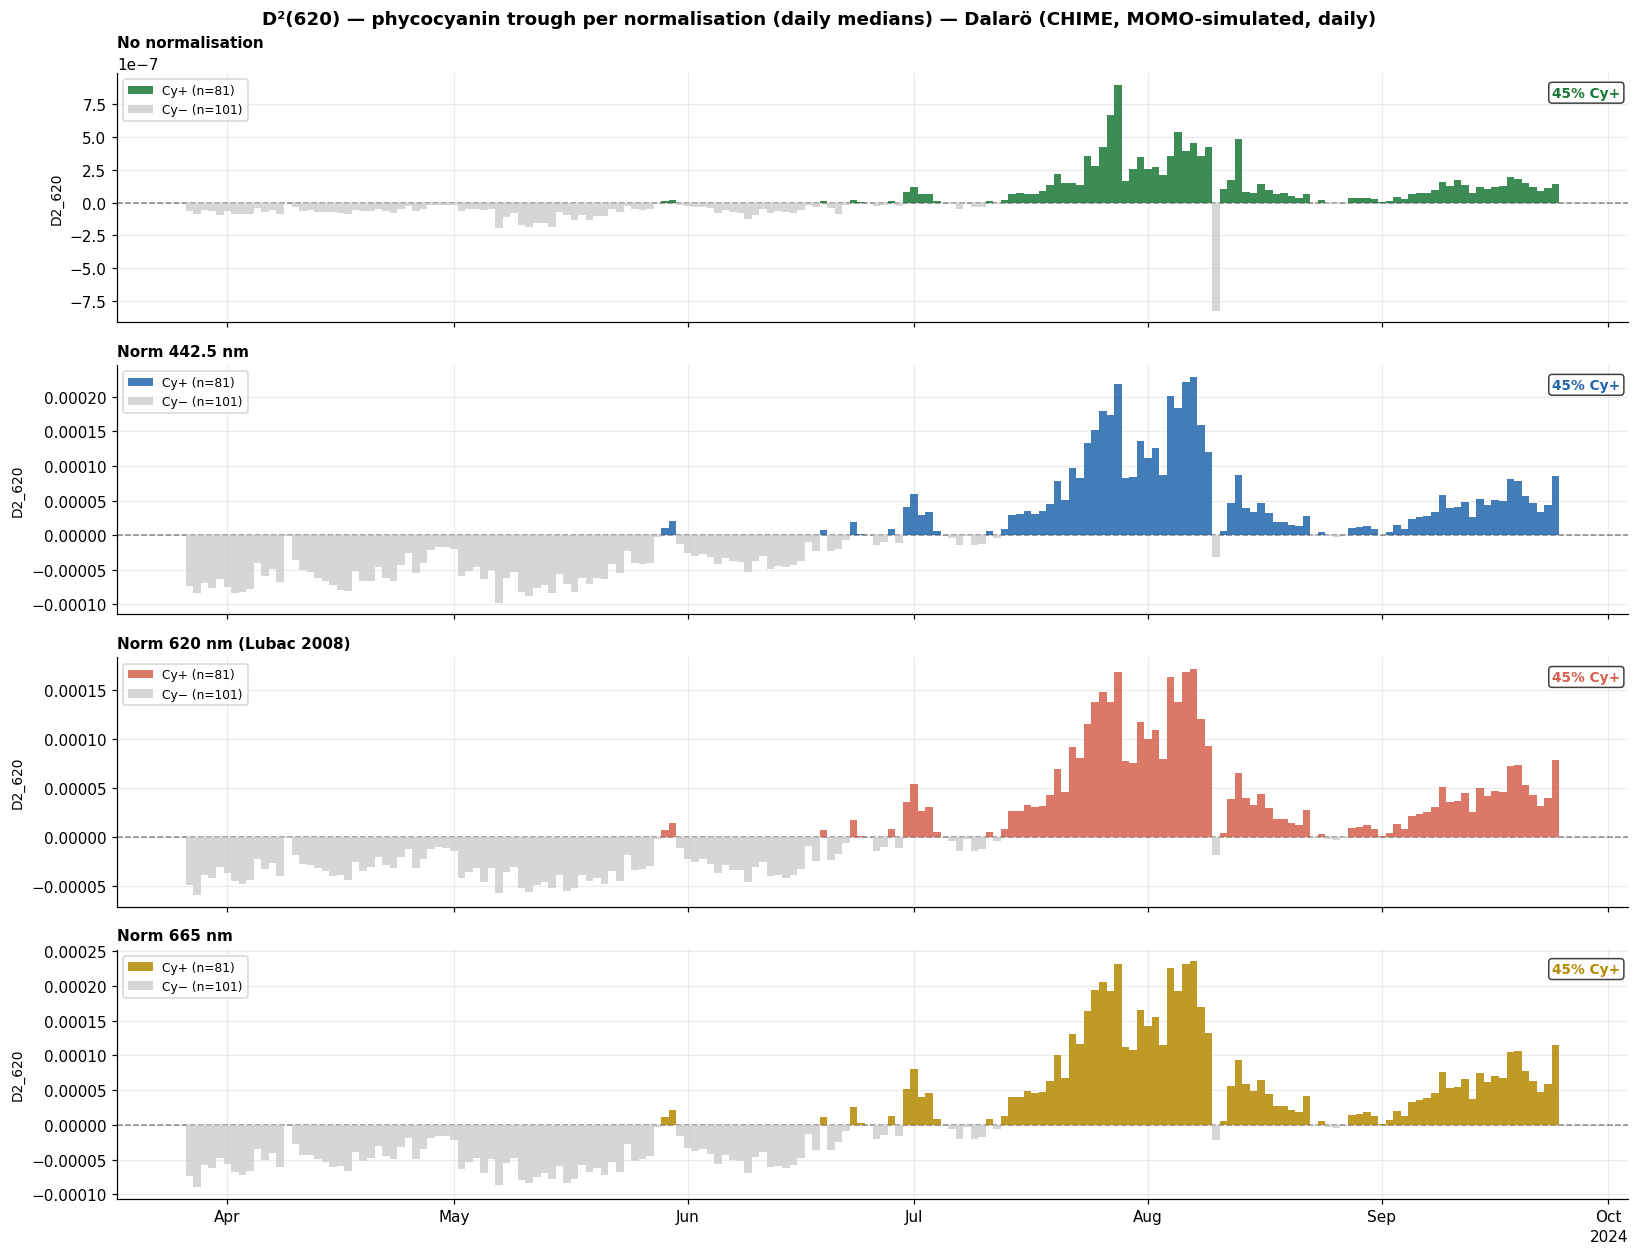

In [150]:
feat = SENS_FEATURE; thr, sgn = RULES[feat]
x = pd.DatetimeIndex(DM['raw'].index)
w = 1.0 if len(x) > 150 else 2.5
fig, axes = plt.subplots(len(NORM_OK), 1, figsize=(15, 2.9 * len(NORM_OK)), sharex=True, squeeze=False)
for ax, (key, nw, lbl, col) in zip(axes[:, 0], NORM_OK):
    v = DM[key][feat].values
    fin = np.isfinite(v); cyp = fin & (sgn * (v - thr) > 0); cym = fin & ~cyp
    ax.axhline(thr, color='k', lw=1, ls='--', alpha=0.45, zorder=2)
    ax.bar(x[cyp], v[cyp], width=w, color=col, alpha=0.85, label=f'Cy+ (n={cyp.sum()})', zorder=3)
    ax.bar(x[cym], v[cym], width=w, color='#cccccc', alpha=0.8, label=f'Cy− (n={cym.sum()})', zorder=3)
    ax.set_title(lbl, fontsize=10, loc='left', fontweight='bold'); ax.set_ylabel(f'{feat}', fontsize=9)
    ax.text(0.995, 0.95, f'{100 * cyp.sum() / max(fin.sum(), 1):.0f}% Cy+', transform=ax.transAxes, ha='right',
            va='top', fontsize=9, color=col, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', alpha=0.75))
    ax.legend(fontsize=8, loc='upper left', framealpha=0.8)
loc = mdates.AutoDateLocator()
axes[-1, 0].xaxis.set_major_locator(loc); axes[-1, 0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
fig.suptitle(f'{FEAT_LABEL[feat]} per normalisation (daily medians) — {STATION}', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.savefig(fig_path(f'4_norm_timeseries_{feat}'), dpi=150, bbox_inches='tight'); plt.show()

### 11.3 Monthly distribution per normalisation
Daily medians grouped by calendar month (years pooled). Boxes for months with ≥ 3 days, points otherwise;
▲ marks months whose median satisfies the Cy+ rule.

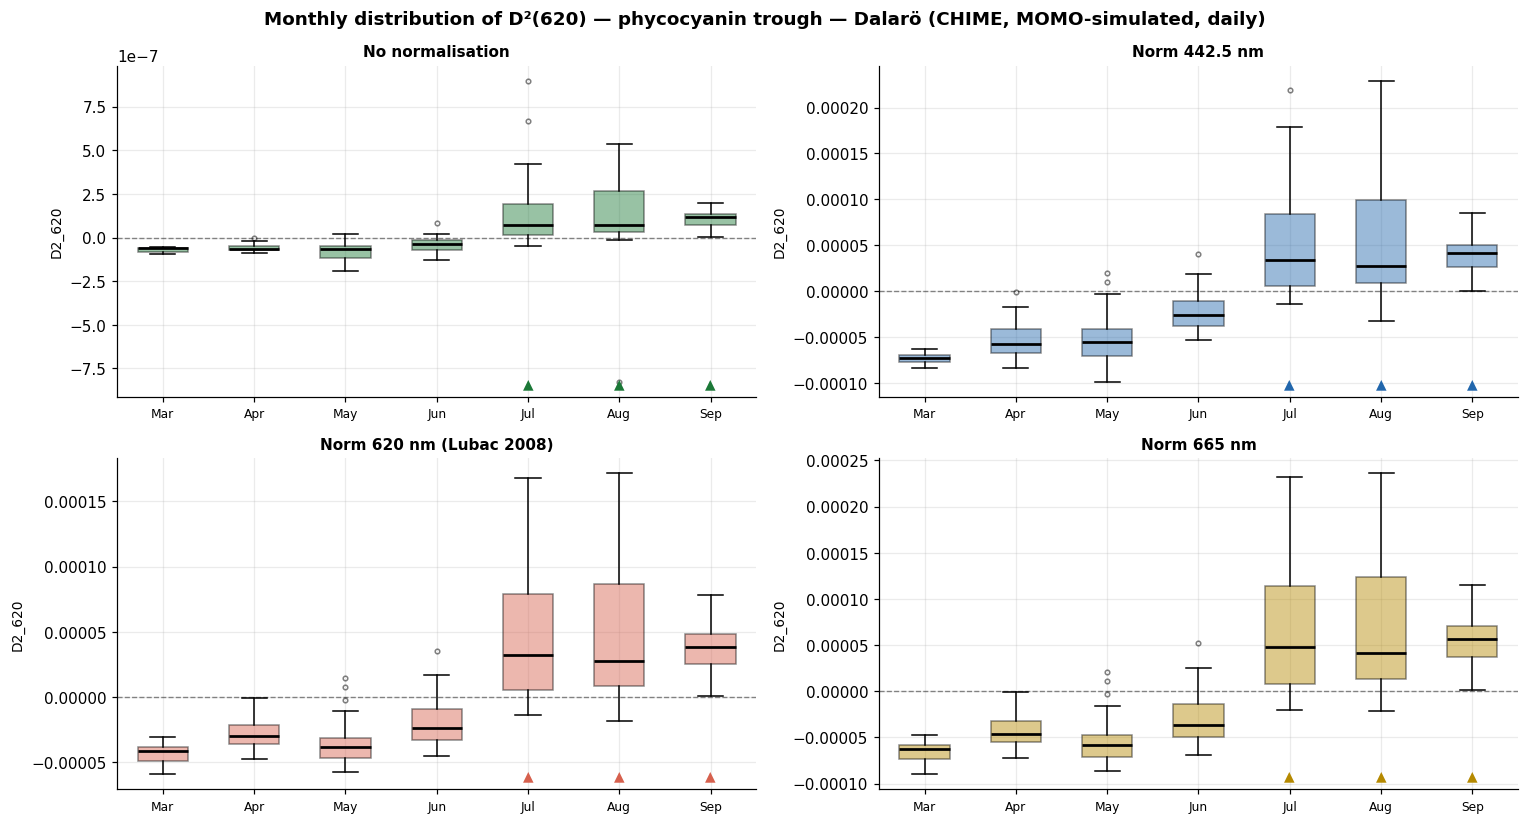

In [151]:
MONTH_LABELS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
MIN_OBS = 3
months_arr = x.month.values
months_present = sorted(set(months_arr))
ncols = 2; nrows = int(np.ceil(len(NORM_OK) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.8 * nrows), squeeze=False)
for ax, (key, nw, lbl, col) in zip(axes.flat, NORM_OK):
    v = DM[key][feat].values
    for k, mth in enumerate(months_present, start=1):
        vals = v[(months_arr == mth) & np.isfinite(v)]
        if vals.size == 0:
            continue
        if vals.size >= MIN_OBS:
            bp = ax.boxplot([vals], positions=[k], widths=0.55, patch_artist=True,
                            medianprops=dict(color='k', lw=1.8), flierprops=dict(marker='o', markersize=3, alpha=0.5))
            bp['boxes'][0].set_facecolor(col); bp['boxes'][0].set_alpha(0.45)
        else:
            ax.scatter([k] * vals.size, vals, color=col, s=40, edgecolors='k', linewidths=0.5, zorder=5)
        if sgn * (np.median(vals) - thr) > 0:
            ax.text(k, 0.02, '▲', transform=ax.get_xaxis_transform(), ha='center', va='bottom', color=col, fontsize=9)
    ax.axhline(thr, color='k', lw=0.9, ls='--', alpha=0.45)
    ax.set_xticks(range(1, len(months_present) + 1))
    ax.set_xticklabels([MONTH_LABELS[mth - 1] for mth in months_present], fontsize=8)
    ax.set_xlim(0.5, len(months_present) + 0.5)
    ax.set_title(lbl, fontsize=10, fontweight='bold'); ax.set_ylabel(feat, fontsize=9)
for ax in list(axes.flat)[len(NORM_OK):]:
    ax.set_visible(False)
fig.suptitle(f'Monthly distribution of {FEAT_LABEL[feat]} — {STATION}', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.savefig(fig_path(f'5_norm_monthly_{feat}'), dpi=150, bbox_inches='tight'); plt.show()

### 11.4 Cross-normalisation comparison
Each pair of normalisations: sign agreement (blue = same sign, red = different) and rank / linear correlation.
The axes have different units, so no 1:1 line is drawn.

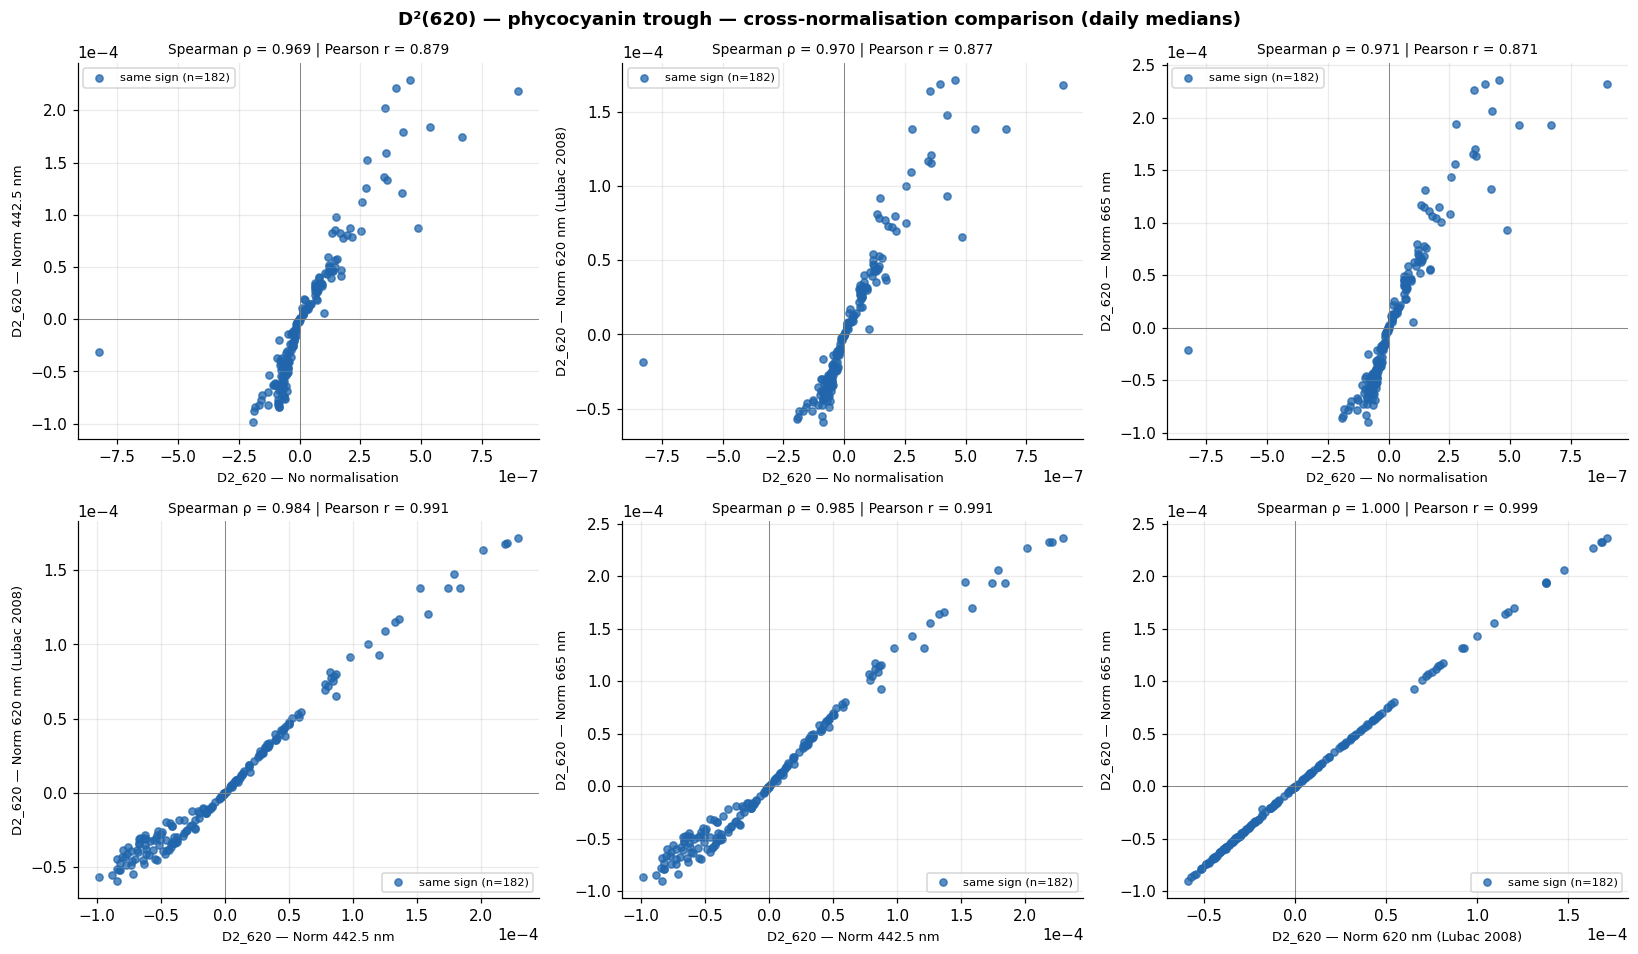

In [152]:
pairs = list(combinations([k for k, *_ in NORM_OK], 2))
if pairs:
    ncols = min(3, len(pairs)); nrows = int(np.ceil(len(pairs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.4 * nrows), squeeze=False)
    for ax, (ka, kb) in zip(axes.flat, pairs):
        xa, xb = DM[ka][feat].values, DM[kb][feat].values
        fin = np.isfinite(xa) & np.isfinite(xb)
        same = np.sign(xa) == np.sign(xb)
        ax.scatter(xa[fin & same], xb[fin & same], color='#2166ac', s=22, alpha=0.75,
                   label=f'same sign (n={int((fin & same).sum())})')
        if (fin & ~same).any():
            ax.scatter(xa[fin & ~same], xb[fin & ~same], color='#d6604d', s=40, marker='X', zorder=5,
                       label=f'different sign (n={int((fin & ~same).sum())})')
        ax.axhline(0, color='gray', lw=0.6); ax.axvline(0, color='gray', lw=0.6)
        if fin.sum() >= 3:
            rs = spearmanr(xa[fin], xb[fin])[0]; rp = np.corrcoef(xa[fin], xb[fin])[0, 1]
            ax.set_title(f'Spearman ρ = {rs:.3f} | Pearson r = {rp:.3f}', fontsize=9)
        ax.set_xlabel(f'{feat} — {NORM_LABEL[ka]}', fontsize=8.5); ax.set_ylabel(f'{feat} — {NORM_LABEL[kb]}', fontsize=8.5)
        ax.ticklabel_format(axis='both', style='sci', scilimits=(-3, 3))
        ax.legend(fontsize=7.5, framealpha=0.8)
    for ax in list(axes.flat)[len(pairs):]:
        ax.set_visible(False)
    fig.suptitle(f'{FEAT_LABEL[feat]} — cross-normalisation comparison (daily medians)', fontsize=12, fontweight='bold')
    plt.tight_layout(); plt.savefig(fig_path(f'6_norm_scatter_{feat}'), dpi=150, bbox_inches='tight'); plt.show()

### 11.5 D²(λ) profiles for selected dates
Representative spectrum of six dates spread over the series. Each D² curve is scaled to its own maximum |D²| in
500–700 nm so that the shapes can be compared; the scaling is positive and keeps the sign.

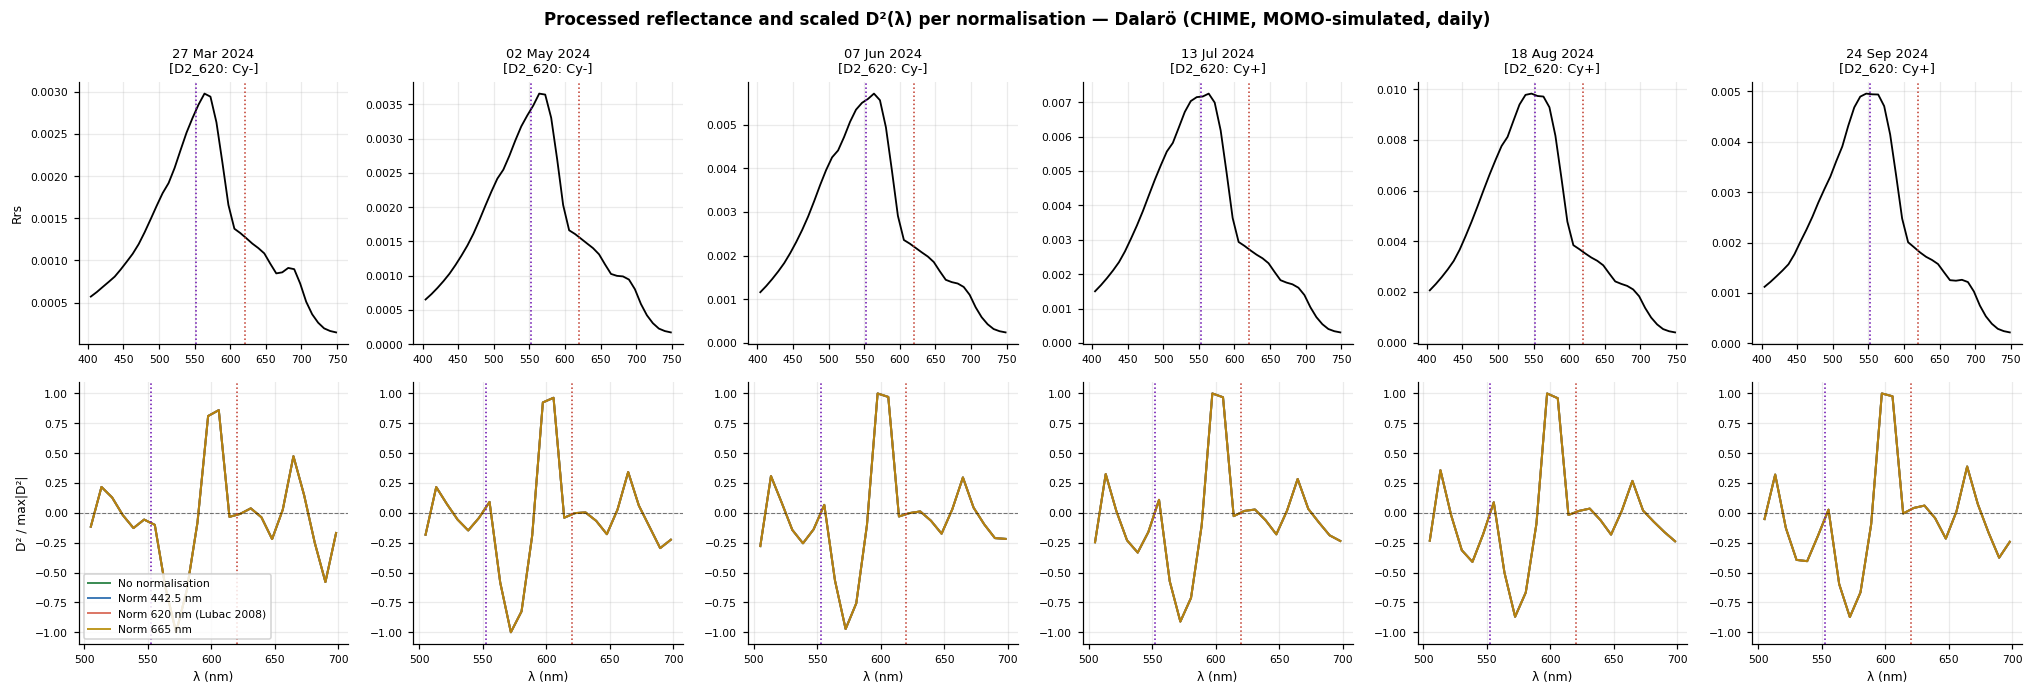

In [153]:
n_show = min(6, len(day))
sel_days = pd.DatetimeIndex(day.index)[np.linspace(0, len(day) - 1, n_show).astype(int)]
fig, axes = plt.subplots(2, n_show, figsize=(3.1 * n_show, 6.4), squeeze=False)
m_r = (wlp >= 400) & (wlp <= 750); m_d = (wlp >= 500) & (wlp <= 700)
for c_, d_ in enumerate(sel_days):
    i = rep_index(d_, feat)
    ax_r, ax_d = axes[0, c_], axes[1, c_]
    ax_r.plot(wlp[m_r], Rp[i, m_r], 'k-', lw=1.2)
    for key, nw, lbl, col in NORM_OK:
        d2 = D2CUBE[key][i, m_d]; s_ = np.nanmax(np.abs(d2))
        if np.isfinite(s_) and s_ > 0:
            ax_d.plot(wlp[m_d], d2 / s_, color=col, lw=1.3, alpha=0.85, label=lbl if c_ == 0 else None)
    ax_d.axhline(0, color='k', lw=0.7, ls='--', alpha=0.5)
    for lam, _, co in MARK:
        ax_r.axvline(lam, color=co, ls=':', lw=1); ax_d.axvline(lam, color=co, ls=':', lw=1)
    cls_txt = day.loc[d_, MAIN_FEATURE + '_class']
    ax_r.set_title(f'{d_:%d %b %Y}\n[{MAIN_FEATURE}: {cls_txt}]', fontsize=8.5)
    ax_r.tick_params(labelsize=7); ax_d.tick_params(labelsize=7); ax_d.set_xlabel('λ (nm)', fontsize=8)
    ax_d.set_ylim(-1.1, 1.1)
axes[0, 0].set_ylabel(DS['refl'], fontsize=8); axes[1, 0].set_ylabel('D² / max|D²|', fontsize=8)
axes[1, 0].legend(fontsize=7, loc='lower left', framealpha=0.85)
fig.suptitle(f'Processed reflectance and scaled D²(λ) per normalisation — {STATION}', fontsize=11, fontweight='bold')
plt.tight_layout(); plt.savefig(fig_path('7_norm_profiles'), dpi=150, bbox_inches='tight'); plt.show()

### 11.6 Extreme cases
Days with the strongest and weakest Cy+ signal of `SENS_FEATURE`. Every day is first screened for temporal consistency:
a day whose sign disagrees with most of its neighbours within ±14 days, or that has fewer than 2 neighbours, is flagged
as isolated/unverifiable and cannot be chosen. The ranking uses the 620 nm normalisation (shape-based, independent of
the absolute reflectance level); the sign — and therefore the screening — is the same for every normalisation.

Flagged as isolated/unverifiable: 3 of 182 days: ['2024-05-29', '2024-05-30', '2024-08-10']
Strongest Cy+ signal: 07 Aug 2024 | weakest: 28 Mar 2024  (ranking: Norm 620 nm (Lubac 2008))


,strongest 2024-08-07,weakest 2024-03-28
No normalisation,+4.545e-07,-8.491e-08
Norm 442.5 nm,+2.292e-04,-8.399e-05
Norm 620 nm (Lubac 2008),+1.715e-04,-5.909e-05
Norm 665 nm,+2.361e-04,-8.997e-05


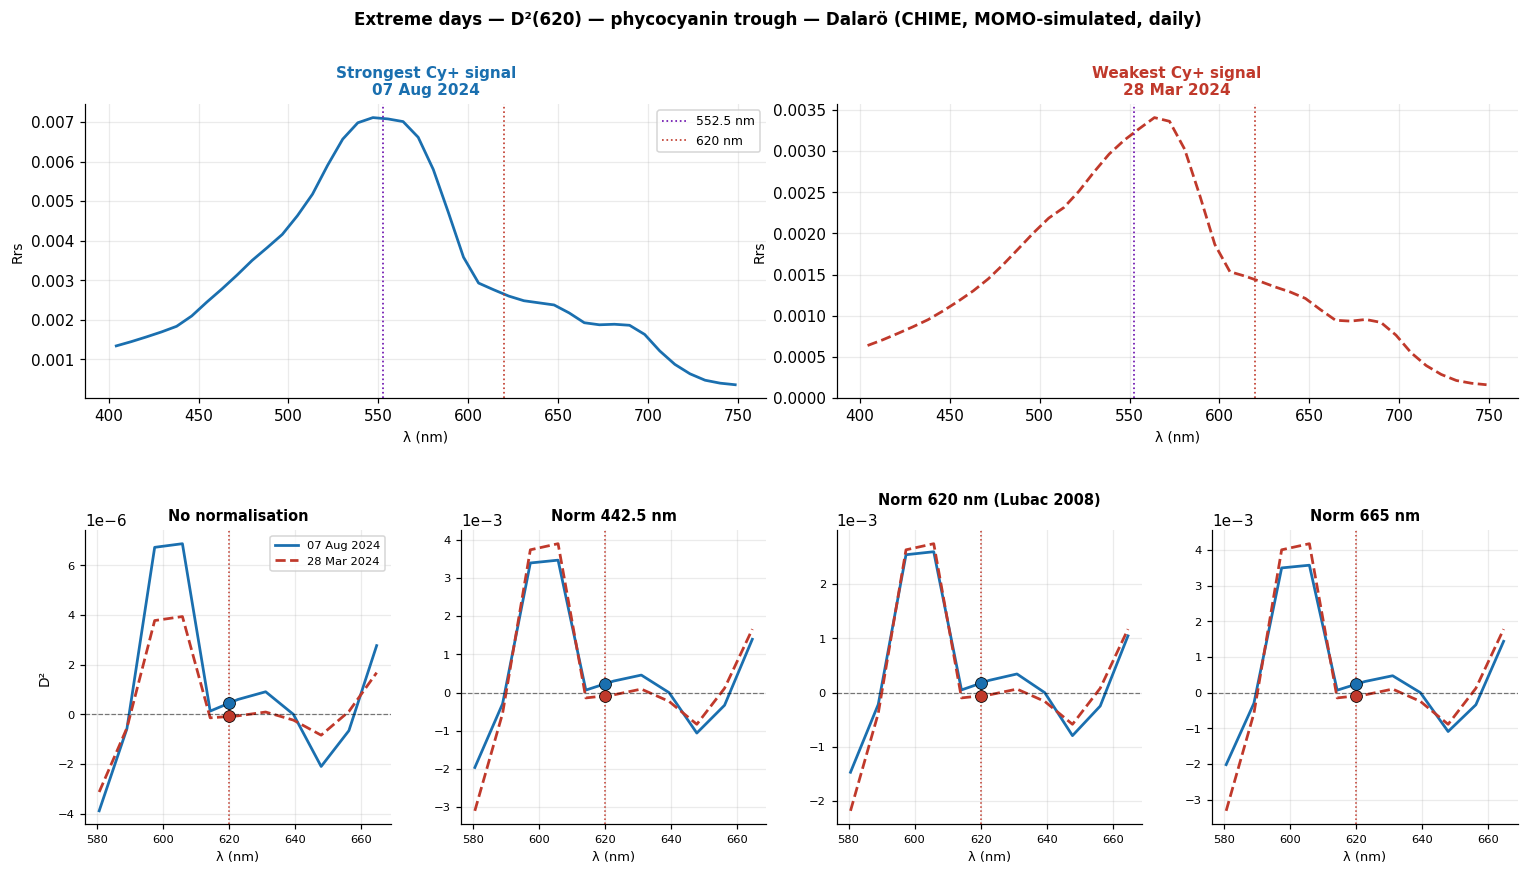

In [154]:
def flag_isolated(values, days, window_days=14, min_agree=2):
    """True = isolated/unverifiable: fewer than min_agree neighbours within ±window_days share the sign."""
    v = np.asarray(values, float); d = pd.DatetimeIndex(days).values.astype('datetime64[D]')
    win = np.timedelta64(window_days, 'D'); out = np.zeros(v.size, bool)
    for i in range(v.size):
        if not np.isfinite(v[i]):
            out[i] = True; continue
        nb = (np.abs(d - d[i]) <= win) & (np.arange(v.size) != i) & np.isfinite(v)
        out[i] = nb.sum() < min_agree or int((np.sign(v[nb]) == np.sign(v[i])).sum()) < min_agree
    return out

EXTREME_REF = '620' if '620' in DM else 'raw'
days_ix = pd.DatetimeIndex(DM['raw'].index)
isolated = flag_isolated(DM['raw'][feat].values, days_ix)
print(f'Flagged as isolated/unverifiable: {isolated.sum()} of {len(days_ix)} days'
      + (f': {[str(d_.date()) for d_ in days_ix[isolated]][:20]}' + (' …' if isolated.sum() > 20 else '')
         if isolated.any() else ''))

score = sgn * DM[EXTREME_REF][feat].values
score = np.where(isolated, np.nan, score)
EXTREMES = None
if np.isfinite(score).sum() >= 2:
    d_cy, d_no = days_ix[int(np.nanargmax(score))], days_ix[int(np.nanargmin(score))]
    EXTREMES = (d_cy, d_no)
    print(f'Strongest Cy+ signal: {d_cy:%d %b %Y} | weakest: {d_no:%d %b %Y}  (ranking: {NORM_LABEL[EXTREME_REF]})')
    display(pd.DataFrame({lbl: [DM[k].loc[d_cy, feat], DM[k].loc[d_no, feat]] for k, lbl in NORM_LABEL.items()},
                         index=[f'strongest {d_cy:%Y-%m-%d}', f'weakest {d_no:%Y-%m-%d}']).T.style.format('{:+.3e}'))

    cases = [(d_cy, 'Strongest Cy+ signal', '#1a6faf', '-'), (d_no, 'Weakest Cy+ signal', '#c0392b', '--')]
    nN = len(NORM_OK)
    fig = plt.figure(figsize=(max(12, 4.2 * nN), 8.5))
    gs = gridspec.GridSpec(2, 2 * nN, figure=fig, hspace=0.45, wspace=0.6)
    lam = FEAT_WL[feat]; m_d = (wlp >= lam - 45) & (wlp <= lam + 45)
    for c_, (d_, ttl, lc, ls) in enumerate(cases):
        i = rep_index(d_, feat)
        ax = fig.add_subplot(gs[0, c_ * nN:(c_ + 1) * nN])
        ax.plot(wlp[m_r], Rp[i, m_r], color=lc, lw=1.8, ls=ls)
        for lam_, lbl_, co in MARK:
            ax.axvline(lam_, color=co, lw=1.1, ls=':', label=lbl_ if c_ == 0 else None)
        ins = ''
        if MU is not None and (MU.spec_day == d_).any():
            ins = f' — in situ {MU.loc[MU.spec_day == d_, "cy_frac"].iloc[0]:.0%} cyano'
        ax.set_title(f'{ttl}\n{d_:%d %b %Y}{ins}', fontsize=10, fontweight='bold', color=lc)
        ax.set_xlabel('λ (nm)', fontsize=9); ax.set_ylabel(DS['refl'], fontsize=9)
        if c_ == 0:
            ax.legend(fontsize=8, loc='upper right')
    for n_, (key, nw, lbl, col) in enumerate(NORM_OK):
        ax = fig.add_subplot(gs[1, 2 * n_:2 * n_ + 2])
        for d_, ttl, lc, ls in cases:
            i = rep_index(d_, feat)
            ax.plot(wlp[m_d], D2CUBE[key][i, m_d], color=lc, lw=1.8, ls=ls, label=f'{d_:%d %b %Y}')
            ax.scatter([lam], [DM[key].loc[d_, feat]], color=lc, s=60, zorder=6, edgecolors='k', linewidths=0.5)
        ax.axhline(0, color='k', lw=0.8, ls='--', alpha=0.5); ax.axvline(lam, color=FEAT_COL[feat], lw=1, ls=':')
        ax.set_title(lbl, fontsize=9.5, fontweight='bold'); ax.set_xlabel('λ (nm)', fontsize=8.5)
        ax.ticklabel_format(axis='y', style='sci', scilimits=(-3, 3)); ax.tick_params(labelsize=7.5)
        if n_ == 0:
            ax.set_ylabel('D²', fontsize=9); ax.legend(fontsize=7.5, loc='best')
    fig.suptitle(f'Extreme days — {FEAT_LABEL[feat]} — {STATION}', fontsize=11, fontweight='bold')
    plt.savefig(fig_path(f'8_norm_extremes_{feat}'), dpi=150, bbox_inches='tight'); plt.show()
else:
    print('Not enough temporally consistent days to select extreme cases.')

## 12. Scale sensitivity
The same features are recomputed for a range of smoothing widths (target effective resolution). A robust feature
gives a Cy+ fraction — and, with in-situ data, a false-positive rate and AUC — that are stable across scales.

This is a **sensitivity analysis, not a tuning step**: the processing scale is fixed a priori (`SMOOTH_FWHM`).
Choosing the scale that maximises these metrics on the same match-ups would bias them.

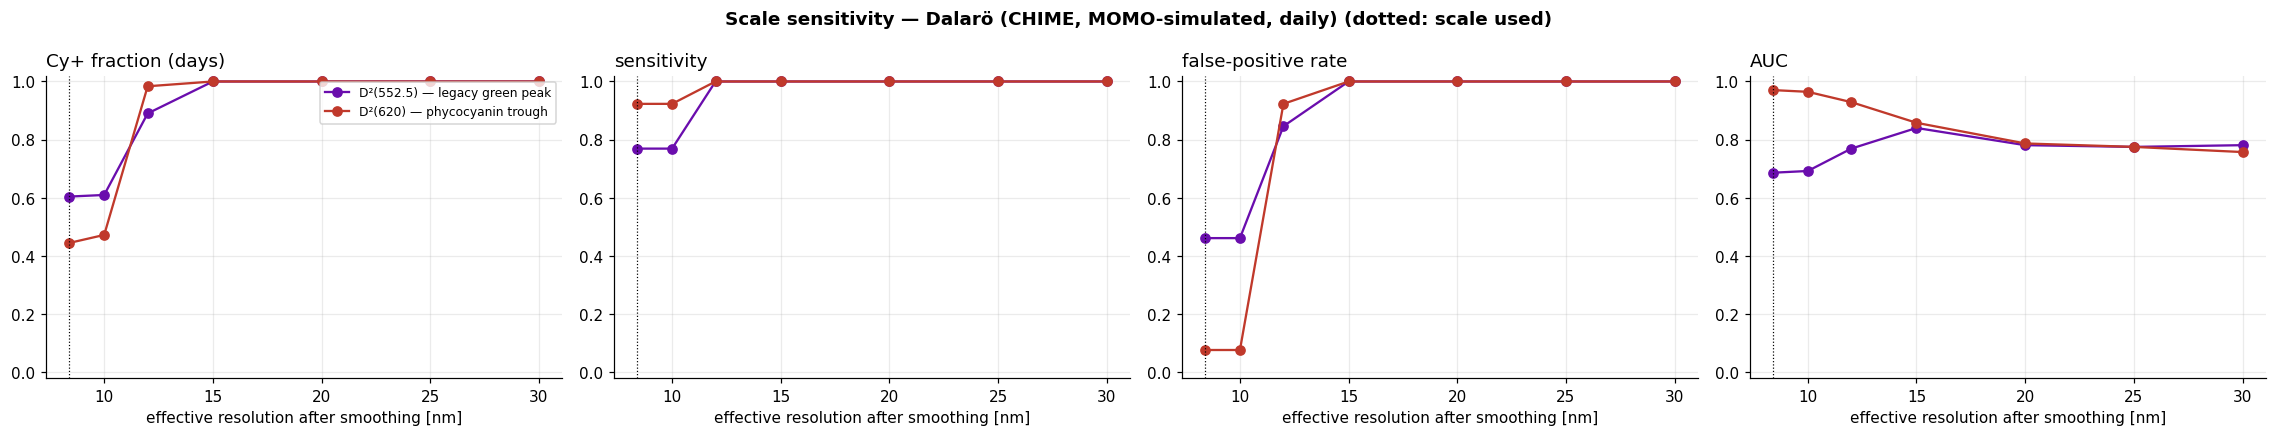

Cy+ fraction (days)        sensitivity        false-positive rate  \
feature                 D2_552 D2_620      D2_552 D2_620              D2_552   
scale [nm]                                                                     
8.4                       0.60   0.45        0.77   0.92                0.46   
10.0                      0.61   0.47        0.77   0.92                0.46   
12.0                      0.89   0.98        1.00   1.00                0.85   
15.0                      1.00   1.00        1.00   1.00                1.00   
20.0                      1.00   1.00        1.00   1.00                1.00   
25.0                      1.00   1.00        1.00   1.00                1.00   
30.0                      1.00   1.00        1.00   1.00                1.00   

                     AUC         
feature    D2_620 D2_552 D2_620  
scale [nm]                       
8.4          0.08   0.69   0.97  
10.0         0.08   0.69   0.96  
12.0         0.92   0.77   0.93  
15.0         1.00   0.84   0.86  
20.0         1.00   0.78   0.79  
25.0         1.00   0.78   0.78  
30.0         1.00   0.78   0.76

In [155]:
SCALES = [None] + [F for F in (5, 7.5, 10, 12, 15, 20, 25, 30) if F > INFO['native_resolution'] + 0.5]
rows = []
for F in SCALES:
    fs, fi = cy.cyano_features(RHOW, wl, smooth_fwhm=F, native_fwhm=DS['native_fwhm'], norm_wl=NORM_WL)
    dm = pd.DataFrame({'date': dates.values, **{f: np.asarray(fs[f], float) for f in FEATS_ALL}}).groupby('date').median()
    for f in FEATS_ALL:
        thr, sgn = RULES[f]
        r = {'scale [nm]': INFO['native_resolution'] if F is None else F, 'feature': f,
             'Cy+ fraction (days)': float((sgn * (dm[f] - thr) > 0).mean())}
        if MU is not None:
            v = dm[f].reindex(MU.spec_day).values; domv = MU.cy_dom.values
            pos = sgn * (v - thr) > 0
            r['sensitivity'] = pos[domv].mean() if domv.any() else np.nan
            r['false-positive rate'] = pos[~domv].mean() if (~domv).any() else np.nan
            r['AUC'] = auc(sgn * v, domv)
        rows.append(r)
SWEEP = pd.DataFrame(rows)
metrics = [c for c in ('Cy+ fraction (days)', 'sensitivity', 'false-positive rate', 'AUC')
           if c in SWEEP and SWEEP[c].notna().any()]
fig, axes = plt.subplots(1, len(metrics), figsize=(5.2 * len(metrics), 4), squeeze=False)
for ax, mcol in zip(axes[0], metrics):
    for f, g_ in SWEEP.groupby('feature'):
        if g_[mcol].isna().all():
            continue
        ax.plot(g_['scale [nm]'], g_[mcol], 'o-', color=FEAT_COL[f], label=FEAT_LABEL[f])
    ax.axvline(INFO['effective_resolution'], color='k', ls=':', lw=0.8)
    ax.set_ylim(-0.02, 1.02); ax.set_xlabel('effective resolution after smoothing [nm]'); ax.set_title(mcol, loc='left')
axes[0, 0].legend(fontsize=8)
fig.suptitle(f'Scale sensitivity — {STATION} (dotted: scale used)', fontweight='bold')
plt.tight_layout(); plt.savefig(fig_path('9_scale_sensitivity'), dpi=150, bbox_inches='tight'); plt.show()
display(SWEEP.pivot(index='scale [nm]', columns='feature', values=metrics).round(2))

### 12.1 Cy− days at native resolution (measured spectra only)
Without smoothing, D²(620) is noisier. If the Cy− days at native resolution were real periods without
cyanobacteria, they would cluster in low-cyanobacteria months; if they are spread over all months, including
those with a high in-situ share, they reflect measurement noise that the processing scale removes.

In [156]:
if DS['simulated']:
    print('Simulated spectra are not smoothed: the native-resolution check is not applicable.')
else:
    fs0, _ = cy.cyano_features(RHOW, wl, smooth_fwhm=None, native_fwhm=DS['native_fwhm'], norm_wl=NORM_WL)
    d0 = pd.Series(np.asarray(fs0['D2_620'], float), index=dates.values).groupby(level=0).median()
    neg = d0 <= 0
    print(f'D²(620) Cy− days at native resolution: {int(neg.sum())} / {len(d0)}')
    tab = neg.groupby(pd.DatetimeIndex(d0.index).to_period('M')).agg(['sum', 'size'])
    tab.columns = ['Cy− days (native)', 'days']
    if INS is not None:
        tab['in-situ cyano share'] = (INS.cy_frac.groupby(INS.index.to_period('M')).median()
                                      .reindex(tab.index).map(lambda v: f'{v:.0%}' if pd.notna(v) else '—'))
    tab.index.name = 'month'
    display(tab)

Simulated spectra are not smoothed: the native-resolution check is not applicable.


## 13. Example spectra
Up to three Cy+ and three Cy− days according to the main feature (largest |value − threshold| among determined
days; days with an in-situ sample are preferred), with the processed reflectance and D²(λ).

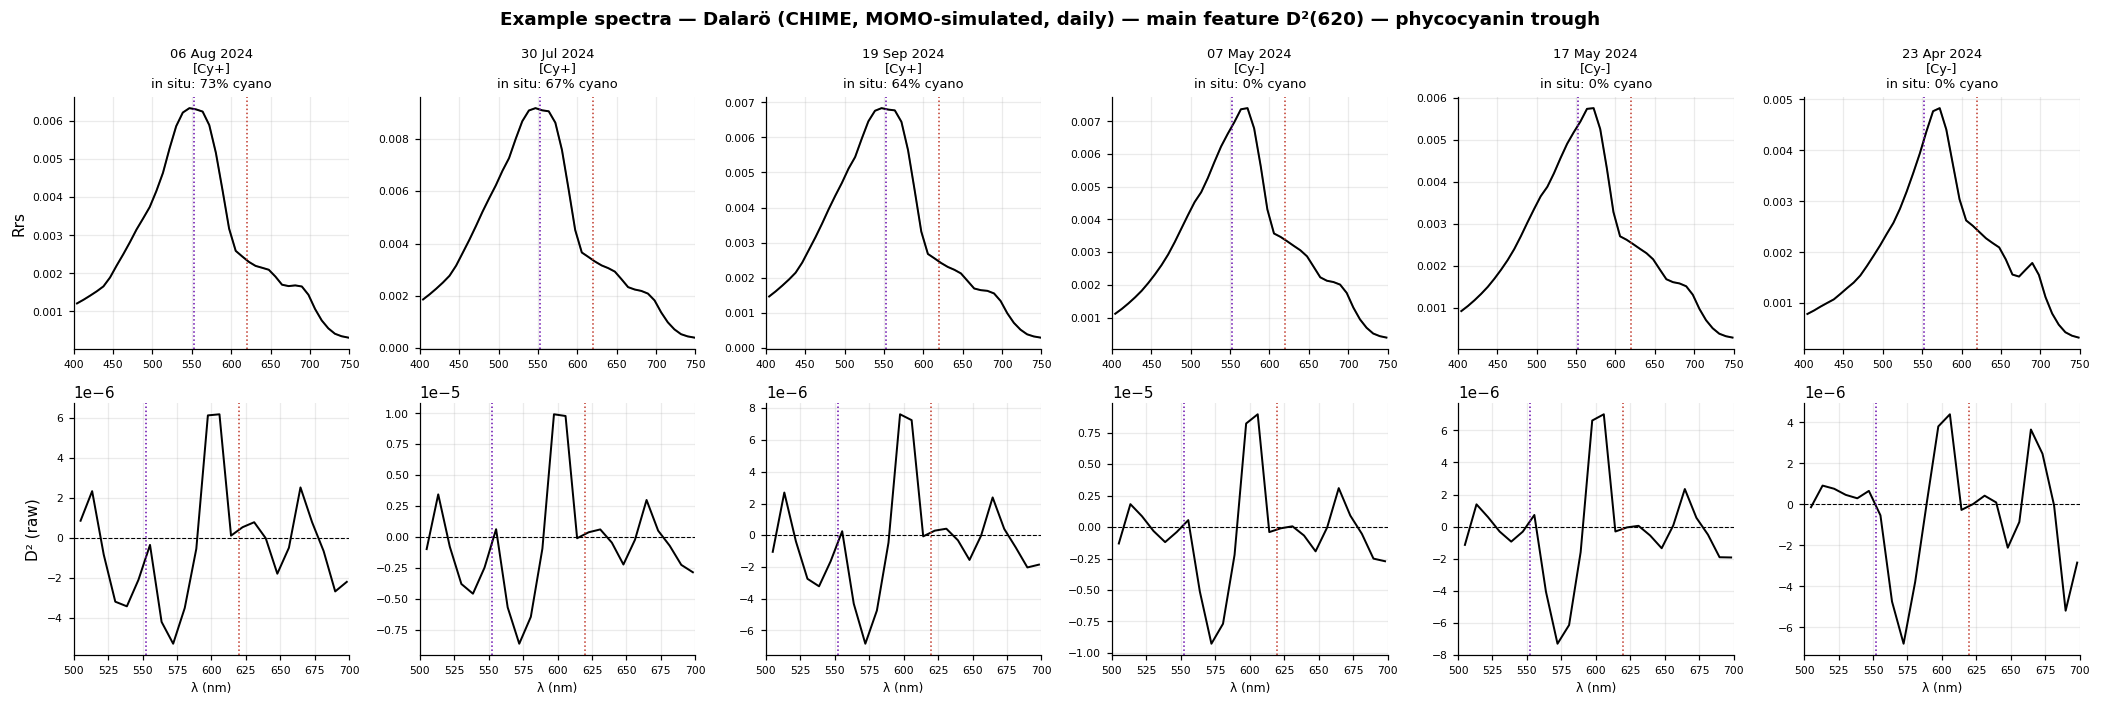

In [157]:
thr, sgn = RULES[MAIN_FEATURE]
det = day[day[MAIN_FEATURE + '_class'] != 'undetermined']
if MU is not None:
    with_insitu = det[det.index.isin(MU.spec_day)]
    if (with_insitu[MAIN_FEATURE + '_class'] == 'Cy+').any() and (with_insitu[MAIN_FEATURE + '_class'] == 'Cy-').any():
        det = with_insitu
pick = (list(det[det[MAIN_FEATURE + '_class'] == 'Cy+'][MAIN_FEATURE].sub(thr).abs().nlargest(3).index) +
        list(det[det[MAIN_FEATURE + '_class'] == 'Cy-'][MAIN_FEATURE].sub(thr).abs().nlargest(3).index))
if pick:
    D_all = cy.second_derivative(Rp, wlp)
    fig, axes = plt.subplots(2, len(pick), figsize=(3.2 * len(pick), 6.5), squeeze=False)
    for k, d_ in enumerate(pick):
        i = rep_index(d_, MAIN_FEATURE)
        ax_r, ax_d = axes[0, k], axes[1, k]
        m = (wl >= 400) & (wl <= 750)
        ax_r.plot(wl[m], RHOW[i, m], color='0.7', lw=1)
        mp = (wlp >= 400) & (wlp <= 750)
        ax_r.plot(wlp[mp], Rp[i, mp], 'k-', lw=1.3)
        ins = ''
        if MU is not None and (MU.spec_day == d_).any():
            ins = f'\nin situ: {MU.loc[MU.spec_day == d_, "cy_frac"].iloc[0]:.0%} cyano'
        ax_r.set_title(f'{pd.Timestamp(d_):%d %b %Y}\n[{day.loc[d_, MAIN_FEATURE + "_class"]}]{ins}', fontsize=8.5)
        md_ = (wlp >= 500) & (wlp <= 700)
        ax_d.plot(wlp[md_], D_all[i, md_], 'k-', lw=1.3)
        ax_d.axhline(0, color='k', lw=0.7, ls='--')
        for lam, _, co in MARK:
            ax_r.axvline(lam, color=co, ls=':', lw=1); ax_d.axvline(lam, color=co, ls=':', lw=1)
        ax_r.set_xlim(400, 750); ax_d.set_xlim(500, 700); ax_d.set_xlabel('λ (nm)', fontsize=8)
        ax_r.tick_params(labelsize=7); ax_d.tick_params(labelsize=7)
        if k == 0:
            ax_r.set_ylabel(DS['refl']); ax_d.set_ylabel('D² (raw)')
    fig.suptitle(f'Example spectra — {STATION} — main feature {FEAT_LABEL[MAIN_FEATURE]}', fontweight='bold')
    plt.tight_layout(); plt.savefig(fig_path('10_examples'), dpi=150, bbox_inches='tight'); plt.show()
else:
    print('No determined days to show.')

## 14. Summary
The summary of this run and the tables of §10–§11 are written to `FIGURES_DIR` with the dataset key in the file name;
the last table compares every dataset that has been run with this notebook.

In [158]:
S = {'Station / dataset': f'{STATION} / {DATASET}',
     'Simulated spectra': DS['simulated'],
     'Spectra loaded / valid after QC / days': f'{N_LOADED} / {len(RHOW)} / {len(day)}',
     'QC rejections per test': ', '.join(f'{k} {v}' for k, v in QC_COUNTS.items() if v) or 'none',
     'High-reflectance days kept (flagged)': ', '.join(HIGH_REFL_DAYS) or 'none',
     'Native / effective resolution [nm]': f'{INFO["native_resolution"]:.1f} / {INFO["effective_resolution"]:.1f}',
     'Analysis grid': 'native bands' if COARSE else 'regular 2.5 nm',
     'Formula = phytospec.compute_D2 (max rel. diff)': f'{FORMULA_DIFF:.0e}' if np.isfinite(FORMULA_DIFF) else 'n/a',
     'Sign of D² independent of normalisation': SIGN_OK,
     'Normalisations tested': ', '.join(NORM_LABEL.values()),
     'Noise method': NOISE_METHOD,
     'Pre-flight warnings': '; '.join(checks.loc[checks.status == 'WARN', 'check']) or 'none',
     'In-situ match-ups (dominated / not)': (f'{len(MU)} ({int(MU.cy_dom.sum())} / {int((~MU.cy_dom).sum())})'
                                            if MU is not None else 'none')}
for f in RULES:
    c = day[f + '_class']; det = c != 'undetermined'
    S[f'{f}: Cy+ share of determined days / undetermined'] = \
        f'{(c[det] == "Cy+").mean():.0%} / {(~det).mean():.0%}' if det.any() else 'n/a'
    if f in BAND_SENS:
        S[f'{f}: bracketing bands disagree in sign'] = f'{BAND_SENS[f]:.0%} of spectra'
if VAL_NUM is not None:
    for f in FEATS_ALL:
        v = VAL_NUM.loc[f]
        S[f'{f}: TP / FN / FP / TN'] = f'{int(v.TP)} / {int(v.FN)} / {int(v.FP)} / {int(v.TN)}'
        S[f'{f}: POD / FPR / KSS / AUC [{CI_LEVEL:.0%} CI]'] = (
            f'{_fmt_ci(v.POD, v.POD_lo, v.POD_hi, True)} / {_fmt_ci(v.POFD, v.POFD_lo, v.POFD_hi, True)} / '
            f'{_fmt(v.KSS)} / {_fmt_ci(v.AUC, v.AUC_lo, v.AUC_hi, False)}')
    S['Validation independent of the spectra'] = 'no — simulated spectra' if DS['simulated'] else 'yes'

SUMMARY = pd.Series(S, name='value').to_frame()
SUMMARY.to_csv(FIG_DIR / f'05v2_{DATASET}_summary.csv')
NORM_TAB.to_csv(FIG_DIR / f'05v2_{DATASET}_normalisation.csv', index=False)
if VAL_NUM is not None:
    VAL_NUM.to_csv(FIG_DIR / f'05v2_{DATASET}_validation.csv')
display(SUMMARY)

,value
Station / dataset,"Dalarö (CHIME, MOMO-simulated, daily) / dalaro..."
Simulated spectra,True
Spectra loaded / valid after QC / days,182 / 182 / 182
QC rejections per test,none
High-reflectance days kept (flagged),"2024-08-10, 2024-08-11"
Native / effective resolution [nm],8.4 / 8.4
Analysis grid,native bands
Formula = phytospec.compute_D2 (max rel. diff),4e-14
Sign of D² independent of normalisation,True
Normalisations tested,"No normalisation, Norm 442.5 nm, Norm 620 nm (..."


In [159]:
# ── comparison of every dataset run with this notebook ────────────────────────
files = sorted(FIG_DIR.glob('05v2_*_summary.csv'))
if len(files) > 1:
    comp = pd.concat({f.stem[len('05v2_'):-len('_summary')]: pd.read_csv(f, index_col=0)['value'] for f in files},
                     axis=1, sort=False)
    display(comp.fillna('—'))
else:
    print('Only this dataset has been run so far — rerun the notebook with another DATASET to fill the comparison.')

,dalaro_chime_sim_daily,gorvaln_chime_sim,sodra_wisp,vortsjarv_hypstar
Station / dataset,"Dalarö (CHIME, MOMO-simulated, daily) / dalaro...","Mälaren-Görväln (CHIME, MOMO-simulated) / gorv...",Södra Bergundasjön (WISP) / sodra_wisp,L. Võrtsjärv (Hypstar) / vortsjarv_hypstar
Simulated spectra,True,True,False,False
Spectra loaded / valid after QC / days,182 / 182 / 182,1309 / 1309 / 1309,6375 / 2277 / 181,129 / 127 / 127
QC rejections per test,none,none,"too_bright 23, negative 175, glint 386, time 2...","too_bright 1, negative 1"
High-reflectance days kept (flagged),"2024-08-10, 2024-08-11",none,none,none
Native / effective resolution [nm],8.4 / 8.4,8.4 / 8.4,5.0 / 10.0,3.0 / 10.0
Analysis grid,native bands,native bands,regular 2.5 nm,regular 2.5 nm
Formula = phytospec.compute_D2 (max rel. diff),4e-14,3e-14,7e-15,4e-15
Sign of D² independent of normalisation,True,True,True,True
Normalisations tested,"No normalisation, Norm 442.5 nm, Norm 620 nm (...","No normalisation, Norm 442.5 nm, Norm 620 nm (...","No normalisation, Norm 442.5 nm, Norm 620 nm (...","No normalisation, Norm 442.5 nm, Norm 620 nm (..."
